# Next-Word Prediction Language Model

## Problem Statement

Predicting the next word in a sentence is a fundamental task in Natural Language Processing (NLP). It enables language models to learn patterns, understand word relationships and generate text based on previously observed words.

This project explores how deep learning architectures can learn from text sequences to predict the most likely next word.

## Objective

To build and evaluate next-word prediction models using PyTorch, compare Simple RNN, LSTM, GRU and Transformer architectures, and identify the best-performing model for text generation.

## Dataset

WikiText-2, Word-Level Language Modelling HuggingFace In-buit Dataset

### Table of Contents

1. Imports and Configurations
2. Dataset Loading, Inspection and Exploratory Data Analysis
3. Text Cleaning, Preprocessing and Tokenisation
4. Vocabulary Creation and Numerical Sequence Preparation
5. Dataset Splitting, PyTorch Dataset and DataLoader
6. Build, Train, Validate and Evaluate Simple RNN Model
7. Build, Train, Validate and Evaluate LSTM Model
8. Build, Train, Validate and Evaluate GRU Model
9. Build, Train, Validate and Evaluate Transformer Model
10. Model Comparison and Performance Evaluation
11. Hyperparameter Tuning, Fine-Tuning and Final Model Selection
12. Next-Word Prediction and Text Generation
13. Evaluation on the final Model using Test Dataset
14. Deployment and Documentation


## 1. Imports and Configuration

In [115]:
# -------------------------
# Google Drive and OS
# -------------------------
# Mount Google Drive so we can save our models and project files
from google.colab import drive
import os
drive.mount('/content/drive')

# Create a folder to store model checkpoints
CHECKPOINT_DIR = '/content/drive/MyDrive/Next-Word Prediction NLP/colab_models'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Define checkpoint paths for our four models
RNN_PATH = os.path.join(CHECKPOINT_DIR, 'simple_rnn.pth')
LSTM_PATH = os.path.join(CHECKPOINT_DIR, 'lstm.pth')
GRU_PATH = os.path.join(CHECKPOINT_DIR, 'gru.pth')
TRANSFORMER_PATH = os.path.join(CHECKPOINT_DIR, 'transformer.pth')

# Path for the selected final model
FINAL_MODEL_PATH = os.path.join(CHECKPOINT_DIR, 'final_model.pth')

# -------------------------
# Data Manipulation
# -------------------------
import pandas as pd # Pandas helps us organise and inspect text data in table format
import numpy as np # NumPy provides numerical operations and array manipulation.

# -------------------------
# Text Processing
# -------------------------
import re # Regular expressions help us clean and process text patterns.
from collections import Counter # Counter helps us count word frequencies when building our vocabulary.

# -------------------------
# Data Visualisation
# -------------------------
import matplotlib.pyplot as plt # Matplotlib helps us visualise training loss, accuracy and other results.

# -------------------------
# Reproducibility
# -------------------------
import random # Random controls Python random numbers for reproducible results.
random.seed(42)
np.random.seed(42)

# -------------------------
# PyTorch
# -------------------------
import torch # The main PyTorch library for tensors and deep learning operations.
import torch.nn as nn # Provides neural network building blocks such as RNN, LSTM, GRU and Linear layers.
import torch.nn.functional as F # Provides functions such as softmax, useful for working with model outputs.
import torch.optim as optim # Provides optimisation algorithms such as Adam.
from torch.utils.data import Dataset # Allows us to create a custom PyTorch dataset for our numerical text sequences.
from torch.utils.data import DataLoader # Loads our data in batches during model training and evaluation.
torch.manual_seed(42) # Controls PyTorch random numbers for reproducible results.
# Set random seed for all CUDA devices.
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

torch.backends.cudnn.deterministic = True # Encourages deterministic CUDA operations.
torch.backends.cudnn.benchmark = False # Disables automatic algorithm benchmarking.

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') # Select the available computing device
print("Computing device:", device)

# -------------------------
# Dataset Loading
# -------------------------
# NB:WE will not use train_test_split because WikiText-2 already provides separate training, validation and test splits. We will preserve those official splits.
from datasets import load_dataset # Loads the WikiText-2 dataset directly from Hugging Face.

# -------------------------
# Evaluation Metrics
# -------------------------
from sklearn.metrics import (precision_score, recall_score, f1_score, top_k_accuracy_score, roc_auc_score)#Provides evaluation metrics for comparing our language models

# -------------------------
# Additional Utilities
# -------------------------
import math # Provides mathematical functions, including exponentiation for perplexity.
import time # Helps us measure model training time.
import copy # Allows us to create independent copies of model weights.
from tqdm.auto import tqdm # Displays progress bars during training and evaluation.

# -------------------------
# Reproducibility Confirmation
# -------------------------
print("All libraries imported successfully.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Computing device: cuda
All libraries imported successfully.


## 2. Dataset Loading, Inspection and EDA


WikiText-2 is hosted on Hugging Face and loaded directly into Google Colab using the Datasets library. It contains 3 Parquet files: Training, Validation and Test. We will inspect the dataset structure, sample text entries, missing values, text length and word distribution.

**Training :** will be used to train our four models

**Validation :** will be used to monitor performance, calculate evaluation metrics and select models

**Test :** will be	Reserved for final evaluation of the selected model


**Loading**

In [116]:
# Import pandas for data inspection and manipulation
import pandas as pd

# Import the dataset loading function
from datasets import load_dataset

In [117]:
#  Load WikiText-2 dataset
nlp_dataset = load_dataset( "Salesforce/wikitext", "wikitext-2-v1")

In [118]:
#for training

# We trying to extract the training dataset here (Convert training data into a Pandas DataFrame)
train_df = pd.DataFrame(nlp_dataset["train"])

# Display the first 10 rows
train_df.head(10)

,text
0,
1,= Valkyria Chronicles III = \n
2,
3,Senjō no Valkyria 3 : <unk> Chronicles ( Japa...
4,"The game began development in 2010 , carrying..."
5,"It met with positive sales in Japan , and was..."
6,
7,= = Gameplay = = \n
8,
9,"As with previous <unk> Chronicles games , Val..."


In [119]:
# For validation dataset

# We extract the validation dataset here (Convert validation data into a Pandas DataFrame)
val_df = pd.DataFrame(nlp_dataset["validation"])

# Display the first 10 rows
val_df.head(10)

,text
0,
1,= Homarus gammarus = \n
2,
3,"Homarus gammarus , known as the European lobs..."
4,
5,= = Description = = \n
6,
7,"Homarus gammarus is a large <unk> , with a bo..."
8,The first pair of <unk> is armed with a large...
9,"The <unk> is generally blue above , with spot..."


In [120]:
# For test dataset

# We extract the test dataset here (Convert validation data into a Pandas DataFrame)
test_df = pd.DataFrame(nlp_dataset["test"])

# Display the first 10 rows
test_df.head(10)

,text
0,
1,= Robert <unk> = \n
2,
3,"Robert <unk> is an English film , television ..."
4,"In 2006 , <unk> starred alongside <unk> in th..."
5,
6,= = Career = = \n
7,
8,
9,= = = 2000 – 2005 = = = \n


**Inspect and EDA**

In [121]:
print("Training shape:", train_df.shape)  #how many shape do we have in train dataset (36,718 row, 1 column)
print("Validation shape:", val_df.shape) #how many shape do we have in validation dataset (3,760 row, 1 column)
print("Test shape:", test_df.shape)  # how many shape do we have in test dataset (4,358 row, 1 column)

Training shape: (36718, 1)
Validation shape: (3760, 1)
Test shape: (4358, 1)


In [122]:
print("Training columns:", train_df.columns) #show train dataset column name (text)
print("Validation columns:", val_df.columns)  #show validation dataset column name (text)
print("Test columns:", test_df.columns)  #show test dataset column name (text)

Training columns: Index(['text'], dtype='object')
Validation columns: Index(['text'], dtype='object')
Test columns: Index(['text'], dtype='object')


In [123]:
print("Training missing values:", train_df.isnull().sum()) #checking for any missing value (0)
print("Validation missing values:", val_df.isnull().sum()) #checking for any missing value (0)
print("Test missing values:", test_df.isnull().sum()) #checking for any missing value (0)

Training missing values: text    0
dtype: int64
Validation missing values: text    0
dtype: int64
Test missing values: text    0
dtype: int64


In [124]:
print("Training empty entries:", (train_df["text"] == "").sum()) #checking for any  empty strings or blank row
print("Validation empty entries:", (val_df["text"] == "").sum()) #checking for any empty strings or blank row
print("Test empty entries:", (test_df["text"] == "").sum()) #checking for any empty strings or blank row

Training empty entries: 12951
Validation empty entries: 1299
Test empty entries: 1467


We just observed there are lot of empty row that might be there for seprators,comma or empty line for new paragraph, we will look into this before feeding it to our models

In [125]:
print("Training:", (train_df["text"] == "").mean() * 100) # checking ther percentage of empty space in train (35.27%)
print("Validation:", (val_df["text"] == "").mean() * 100) # checking ther percentage of empty space in validation(34.54%)
print("Test:", (test_df["text"] == "").mean() * 100)# checking ther percentage of empty space in train (33.66%)

Training: 35.27152895037856
Validation: 34.547872340425535
Test: 33.662230380908674


In [126]:
# show the statistics of train_df characters
print(train_df["text"].str.len().describe())

count    36718.000000
mean       292.895446
std        408.489093
min          0.000000
25%          0.000000
50%         33.000000
75%        545.000000
max       3837.000000
Name: text, dtype: float64


In [127]:
# show the statistics of val_df characters
print(val_df["text"].str.len().describe())

count    3760.000000
mean      297.232447
std       401.130801
min         0.000000
25%         0.000000
50%        35.000000
75%       560.250000
max      2210.000000
Name: text, dtype: float64


In [128]:
# show the statistics of test_df characters
print(test_df["text"].str.len().describe())

count    4358.000000
mean      287.307022
std       400.566836
min         0.000000
25%         0.000000
50%        34.000000
75%       519.000000
max      2539.000000
Name: text, dtype: float64


Both shape shape and count are returning the same values so we would like to word count on each dataset

In [129]:
traindf_wordcount = train_df["text"].str.split().str.len() # Split each word seprately and count it lenght for train
valdf_wordcount = val_df["text"].str.split().str.len() #Split each word seprately and count it lenght for validatiom
testdf_wordcount = test_df["text"].str.split().str.len() #Split each word seprately and count it lenght for test

In [130]:
# word count statistice on train
traindf_wordcount.describe()

,text
count,36718.000000
mean,55.882946
std,77.557130
min,0.000000
25%,0.000000
50%,8.000000
75%,102.000000
max,699.000000


In [131]:
# wordcount statistics on validation
valdf_wordcount.describe()

,text
count,3760.000000
mean,56.884574
std,76.035426
min,0.000000
25%,0.000000
50%,9.000000
75%,106.000000
max,429.000000


In [132]:
# wordcount statistics on test
testdf_wordcount.describe()

,text
count,4358.000000
mean,55.349013
std,76.846338
min,0.000000
25%,0.000000
50%,8.000000
75%,99.000000
max,481.000000


We will use counter to check how frequency some particular word appears across the the trainind dataset before modelling , we will focus more on train dataset

In [133]:
from collections import Counter

In [134]:
train_words = " ".join(train_df["text"]).split() #put all words in train_df together, assign token and split it using tokens

word_freq = Counter(train_words) # counts frequently, how many each token occurs.

word_freq.most_common(20) # show the commond word/tokens using .most_common()

[('the', 113161),
 (',', 99913),
 ('.', 73388),
 ('of', 56889),
 ('<unk>', 54625),
 ('and', 50603),
 ('in', 39453),
 ('to', 39190),
 ('a', 34237),
 ('=', 29570),
 ('"', 28309),
 ('was', 20985),
 ('The', 17602),
 ('@-@', 16906),
 ('that', 14135),
 ('as', 14021),
 ("'s", 14002),
 ('on', 13678),
 ('for', 13307),
 ('with', 12606)]

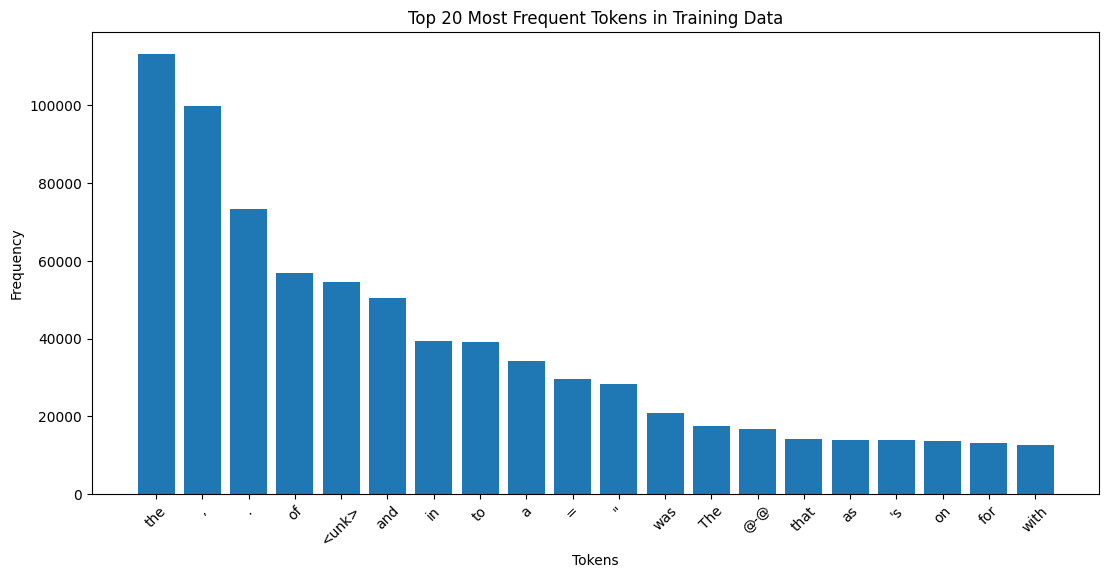

In [135]:
#Visualizing how most common word appears

t_words = word_freq.most_common(20)

words = [item[0] for item in t_words] # show each first item which is word in the var t_words e.g (the, of, unk)
frequencies = [item[1] for item in t_words] #show each second item in counts num, in the the var t_words word e.g (11,3161, 99,913)

plt.figure(figsize=(13, 6))
plt.bar(words, frequencies)
plt.xlabel("Tokens")
plt.ylabel("Frequency")
plt.title("Top 20 Most Frequent Tokens in Training Data")
plt.xticks(rotation=45)
plt.show()

We will check Vocabulary size, the total number of unique tokens in a dataset.

In [136]:
vocab_size = len(word_freq) # count the lenght of unique word in the frequency word_freq

print("Vocabulary size:", vocab_size) # vocabulary size is 33,277 unique token.

Vocabulary size: 33277


## 3. Text Cleaning, Preprocessing and Tokenisation


The goal is to convert our raw WikiText-2 text into a consistent format that PyTorch can eventually work with.

**Cleaning**

In [137]:
train_df = train_df[train_df["text"].str.strip() != ""].copy() #go straight inside train dataset, remove any whitespace or blanks, copy it once done
val_df = val_df[val_df["text"].str.strip() != ""].copy() #go straight inside val dataset, remove any whitespace or blanks, copy it once done
test_df = test_df[test_df["text"].str.strip() != ""].copy() #go straight inside test dataset, remove any whitespace or blanks, copy it once done

In [138]:
#confirming the shapes on train, val and test after whitespace/blank removal
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Training: (23767, 1)
Validation: (2461, 1)
Test: (2891, 1)


Normalise text formatting

We'll convert text to lowercase so that words such as The and the are treated as the same token so we dont have duplicate and to ensure consistency.

In [139]:
train_df["text"] = train_df["text"].str.lower() # For train dataset, convert any string in it to lower case
val_df["text"] = val_df["text"].str.lower() #For train dataset, convert any string in it to lower case
test_df["text"] = test_df["text"].str.lower() # For train dataset, convert any string in it to lower case

In [140]:
# confirming text normalizing
train_df["text"].head(10)

,text
1,= valkyria chronicles iii = \n
3,senjō no valkyria 3 : <unk> chronicles ( japa...
4,"the game began development in 2010 , carrying..."
5,"it met with positive sales in japan , and was..."
7,= = gameplay = = \n
9,"as with previous <unk> chronicles games , val..."
10,"the game 's battle system , the <unk> system ..."
11,troops are divided into five classes : scouts...
13,= = plot = = \n
15,the game takes place during the second europa...


**Tokenization**

In [141]:
# The tokenizing splitting happen here (whitespace-separated tokens, words, Punctuation can also become a token.)

train_tokens = train_df["text"].apply(str.split)  #split every word to a list and apply it to var train_tokens
val_tokens = val_df["text"].apply(str.split) # split every word to a list and apply it to var val_tokens
test_tokens = test_df["text"].apply(str.split) # split every word to a list and apply it to var test_tokens

In [142]:
train_tokens.iloc[0] #confirming firt row in train_tokens


['=', 'valkyria', 'chronicles', 'iii', '=']

In [143]:
test_tokens.iloc[0] #confirming firt row in test_tokens

['=', 'robert', '<unk>', '=']

In [144]:
val_tokens.iloc[0] #confirming firt row in val_tokens

['=', 'homarus', 'gammarus', '=']

In [145]:
total_train_tokens = sum(len(tokens) for tokens in train_tokens) #count all word in each row add it together
total_val_tokens = sum(len(tokens) for tokens in val_tokens) #count all word in each row add it together
total_test_tokens = sum(len(tokens) for tokens in test_tokens) #count all word in each row add it together

print("Training tokens:", total_train_tokens) # show total using the var (2,051,910 tokens)
print("Validation tokens:", total_val_tokens) # show total using the var (213,886 tokens)
print("Test tokens:", total_test_tokens) # show total using the var (2,507,007 tokens)

Training tokens: 2051910
Validation tokens: 213886
Test tokens: 241211


## 4. Vocabulary Creation and Numerical Sequence Preparation

Our Neural networks cannot directly process text. We need to convert our tokens into numerical representations.

In this section, we will:
1. Build a vocabulary from the training data & Assign a unique numerical ID to each token.
2. Handle unknown and padding tokens.
3. Convert our text into numerical sequences.
4. Input and Target Sequence Preparation

A vocabulary is simply a collection of all the unique tokens our model will recognise.

We must not use validation or test data to build our vocabulary. (DataLeakage) Otherwise, information from those datasets could leak into the training process.

1. Build a vocabulary from the training data & Assign a unique numerical ID to each token.


In [146]:
# created train_word_freq var, assigned counter to count each word/token in var train_token
train_word_freq = Counter( token for row in train_tokens for token in row)

print("Vocabulary size:", len(train_word_freq)) # how many unique word found all together (no repeated word)
print("Most common tokens:", train_word_freq.most_common(10)) # show each word with their num of frequency or count

# for better view, we trying to preview train_word_freq in data frame using the colum of token and their frequency
pd.DataFrame(train_word_freq.most_common(10), columns=["Token", "Frequency"])

Vocabulary size: 28911
Most common tokens: [('the', 130768), (',', 99913), ('.', 73388), ('of', 57030), ('<unk>', 54625), ('and', 50735), ('in', 44982), ('to', 39521), ('a', 36156), ('=', 29570)]


,Token,Frequency
0,the,130768
1,",",99913
2,.,73388
3,of,57030
4,<unk>,54625
5,and,50735
6,in,44982
7,to,39521
8,a,36156
9,=,29570


In [147]:
vocab_size = {}  # Create an empty dictionary to store tokens and their numerical IDs

idx = 0  # Set the starting numerical ID to zero

for tok in train_word_freq.keys():  # Loop through every unique token in the training vocabulary
    vocab_size[tok] = idx  # Assign the current numerical ID to the token
    idx = idx + 1  # Increase the ID by one for the next token (the next id become 2, id 3, id 4, id 5, etc)


In [148]:
print("Vocabulary size:", len(vocab_size)) # lenght of numerical id remain the same (28,911)

print("\nFirst 10 Vocabulary Entries:") # serve as heading tittle

for tok, idx in list(vocab_size.items())[:20]:  # Loop through the first 20 token ID
    print(f"{tok:<15} {idx}") # Print each token and its ID with aligned spacing (<15 aligns the tokens neatly by reserving 15 character spaces for each token.)

Vocabulary size: 28911

First 10 Vocabulary Entries:
=               0
valkyria        1
chronicles      2
iii             3
senjō           4
no              5
3               6
:               7
<unk>           8
(               9
japanese        10
戦場のヴァルキュリア3     11
,               12
lit             13
.               14
of              15
the             16
battlefield     17
)               18
commonly        19



2. Handle unknown and padding tokens.

Imagine our model encounters a word during validation or testing that it never saw in the training vocabulary.

How do we represent that word? We need a special token called:
- UNK— Unknown token. Represents a token that isn't in our vocabulary.
- PAD — Padding token. Used later to make sequences have equal lengths.

In [149]:
unk_token = "<unk>"  # Store the unknown token in this variable
pad_token = "<PAD>"  # Store the padding token in this variable

unk_id = vocab_size[unk_token]  # Retrieve the numerical ID assigned to the unknown token

vocab_size[pad_token] = len(vocab_size)  # Assign the next available numerical ID to the padding token
pad_id = vocab_size[pad_token]  # Retrieve the numerical ID assigned to the padding token

print("Updated vocabulary size:", len(vocab_size))  # Display the total number of tokens, including the new padding token (vocabulary size increase by 1, not 2, because <unk> already existed in your vocabulary.)
print("Unknown token ID:", unk_id)  # Display the numerical ID of the unknown token (id 8)
print("Unknown token:", unk_token)  # Display the unknown token itself
print("Padding token ID:", pad_id)  # Display the numerical ID of the padding token (id 28,912) (28911 was the las id before)
print("Padding token:", pad_token)  # Display the padding token itself

Updated vocabulary size: 28912
Unknown token ID: 8
Unknown token: <unk>
Padding token ID: 28911
Padding token: <PAD>



3. Convert our text into numerical sequences list.



Establishing Train_ids ( token become numerical dataset list)

In [150]:
train_ids = []  # Create an empty list to store numerical sequences

for row in train_tokens:  # Loop through each row in the training tokens
    row_ids = []  # Create an empty list to store the numerical IDs for the current row

    for tok in row:  # Loop through each token in the current row
        row_ids.append(vocab_size[tok])  # Retrieve the token's ID and add it to the current row

    train_ids.append(row_ids)  # Add the completed numerical sequence to the training IDs list


In [151]:
print("Original tokens:")
print(train_tokens.iloc[0][:10]) # show the first 10 train_tokens

print("\nNumerical IDs:")
print(train_ids[0][:10]) # show the first 10 train_ids

Original tokens:
['=', 'valkyria', 'chronicles', 'iii', '=']

Numerical IDs:
[0, 1, 2, 3, 0]


Establishing val_ids ( token become numerical dataset list)


In [152]:
val_ids = []  # Create an empty list to store validation numerical sequences

for row in val_tokens:  # Loop through each row in the validation tokens
    row_ids = []  # Create an empty list for the current row's numerical IDs

    for token in row:  # Loop through each token in the current row
        if token in vocab_size:  # Check whether the token exists in our vocabulary
            row_ids.append(vocab_size[token])  # Retrieve and store its numerical ID
        else:
            row_ids.append(unk_id)  # Use the unknown token ID if the token is not found

    val_ids.append(row_ids)  # Store the completed numerical sequence

In [153]:
print("Original tokens:")
print(val_tokens.iloc[0][:10]) # show the first 10 val_tokens

print("\nNumerical IDs:")
print(val_ids[0][:10]) # show the first 10 val_ids

Original tokens:
['=', 'homarus', 'gammarus', '=']

Numerical IDs:
[0, 28618, 28619, 0]


Establishing test_ids ( token become numerical dataset list)


In [154]:
test_ids = []  # Create an empty list to store test numerical sequences

for row in test_tokens:  # Loop through each row in the test tokens
    row_ids = []  # Create an empty list for the current row's numerical IDs

    for token in row:  # Loop through each token in the current row
        if token in vocab_size:  # Check whether the token exists in our vocabulary
            row_ids.append(vocab_size[token])  # Retrieve and store its numerical ID
        else:
            row_ids.append(unk_id)  # Use the unknown token ID if the token is not found

    test_ids.append(row_ids)  # Store the completed numerical sequence

In [155]:
print("Original tokens:")
print(test_tokens.iloc[0][:10]) # show the first 10 test_tokens

print("\nNumerical IDs:")
print(test_ids[0][:10]) # show the first 10 test_ids

Original tokens:
['=', 'robert', '<unk>', '=']

Numerical IDs:
[0, 1066, 8, 0]


In [156]:
example_ids = [10, 25, 40, 55]

input_ids = example_ids[:-1]
target_ids = example_ids[1:]

print("Input IDs:", input_ids)
print("Target IDs:", target_ids)

Input IDs: [10, 25, 40]
Target IDs: [25, 40, 55]


4. Input and Target Sequence Preparation

we will prepare input and target sequences func by shifting our numerical sequences by one position. This allows the model to learn how to predict the next token based on the previous tokens.

In [157]:
context_length = 30

In [158]:
def create_sequences(data, context_length):

    input_sequences = []  # Store the input sequences (contains the tokens the model sees)

    target_sequences = []  # Store the target tokens (contains the next tokens the model should predict)

    for row in data:  # Loop through each numerical sequence

        # Move the sliding window through the sequence
        for i in range(len(row) - context_length):

            input_sequence = row[i:i + context_length]  # Select the context tokens
            target_sequence = row[i + context_length]  # Select the next token

            input_sequences.append(input_sequence)  # Store the input sequence
            target_sequences.append(target_sequence)  # Store the target token

    return input_sequences, target_sequences  # Return both collections as func to euse later

Lets Apply the function to our three datasets

In [159]:
# applying create_sequence() func to train dataset store in a var train_input, train_target
train_input, train_target = create_sequences(train_ids, context_length)

# applying create_sequence() func to train dataset store in a var train_input, train_target
val_input, val_target = create_sequences(val_ids, context_length)

# applying create_sequence() func to train dataset store in a var train_input, train_target
test_input, test_target = create_sequences(test_ids, context_length)

In [160]:
print("Original numerical sequence:")
print(train_ids[0][:5])  # Display the first 5 IDs from the original training id

print("\nGenerated input sequence:")
print(train_input[0])  # Display the first generated input sequence (30 tokens)

print("\nGenerated target token:")
print(train_target[0])  # Display the next token the model should predict

Original numerical sequence:
[0, 1, 2, 3, 0]

Generated input sequence:
[4, 5, 1, 6, 7, 8, 2, 9, 10, 7, 11, 12, 13, 14, 1, 15, 16, 17, 6, 18, 12, 19, 20, 21, 22, 1, 2, 3, 23, 24]

Generated target token:
12


In [161]:
print("Training input sequences:", len(train_input))  # Count the generated training input sequences
print("Training target sequences:", len(train_target))  # Count the generated training target tokens

print("Validation input sequences:", len(val_input))  # Count the generated validation input sequences
print("Validation target sequences:", len(val_target))  # Count the generated validation target tokens

print("Test input sequences:", len(test_input))  # Count the generated test input sequences
print("Test target sequences:", len(test_target))  # Count the generated test target tokens

Training input sequences: 1531747
Training target sequences: 1531747
Validation input sequences: 158707
Validation target sequences: 158707
Test input sequences: 178727
Test target sequences: 178727


## 5. Dataset Splitting, PyTorch Dataset and DataLoader

We have already split our data using the official WikiText-2 training, validation and test sets so no further splitting

We will prepare our numerical sequences for training with PyTorch. We will create PyTorch datasets built custom and DataLoaders to organise our data into batches for efficient model training and evaluation.

In this section, we will:
1. Prepare PyTorch datasets.
2. Create DataLoaders (batch size = 64).
3. Inspect Loaders, batches and their shapes.

1. Prepare PyTorch datasets.

In [162]:
#Time to start using Pytorch tensors coz of conversion to tensor dtypes and custom dataset and loaders
import torch


In [163]:
# Allows us to create a custom built PyTorch dataset to use for model after applying numerical text sequences.
from torch.utils.data import Dataset

In [164]:
#PyTorch needs a structured way to access each input sequence and its corresponding target.
#We achieve this by creating a custom Dataset class. (using PyTorch dataset cutoms)

class NextWordDataset(Dataset):  # Create a custom PyTorch Dataset

    def __init__(self, input_sequences, target_sequences):  # Initialise the dataset
        self.input_sequences = input_sequences  # Store input sequences func
        self.target_sequences = target_sequences  # Store target tokens func

    def __len__(self):
        return len(self.input_sequences) # Return the total number of examples

    def __getitem__(self, index):  # Retrieve an example by its index
        input_sequence = self.input_sequences[index]  # Get the input sequence
        target_sequence = self.target_sequences[index]  # Get its target token

        input_sequence = torch.tensor(input_sequence, dtype=torch.long) # Convert input sequence to a PyTorch tensor
        target_sequence = torch.tensor(target_sequence, dtype=torch.long) #Convert target token to a PyTorch tensor

        return input_sequence, target_sequence  # Return input and target

In [165]:
train_dataset = NextWordDataset(train_input, train_target)#apply pytorch dataset custom to train using the oop class func NextWordDataset()
val_dataset = NextWordDataset(val_input, val_target)# apply pytorch dataset custom to val using the oop class func NextWordDataset()
test_dataset = NextWordDataset(test_input, test_target)#apply pytorch dataset custom to test using the oop class func NextWordDataset()

In [166]:
# checking the shape
print("Training dataset size:", len(train_dataset)) #(1,531,747)
print("Validation dataset size:", len(val_dataset)) #(158,707
print("Test dataset size:", len(test_dataset)) #(178,727)

Training dataset size: 1531747
Validation dataset size: 158707
Test dataset size: 178727


2. Create Dataloaders (batch size = 64)


In [167]:
# Loads our data in batches during model training and evaluation.
from torch.utils.data import DataLoader

In [168]:
#batch_size=64: The model receives 64 (Input sequence and target per batch.)
#NB: Input sequence: (A group of 30 token IDs.) (context)
#NB: Target : (1 word or symbol represented 1 ID.) (next word to predict)
batch_size=64

# for train dataset, we use dataloader func, var batch_size of 64 and shuffle, store in a var called train_loader (Shuffle =True, this helps prevent the model from learning from a fixed data order.)
train_loader = DataLoader( train_dataset, batch_size=batch_size, shuffle=True)

# for validation dataset, we use dataloader func, var batch_size of 64 and No shuffle, store in a var called val_loader
val_loader = DataLoader( val_dataset, batch_size=batch_size, shuffle=False)

#for test dataset, we use dataloader func, var batch_size of 64 and No shuffle, store in a var called test_loader
test_loader = DataLoader( test_dataset, batch_size=batch_size, shuffle=False)

3 Inspect Loaders, batches and their shapes

In [169]:
# Confirmation of our batch dataloader for (train_loader, val_loader, test_loader) through their next batchsize
#NB : each loader represent input_sequence and target_sequence

# Check the training batch
input_batch, target_batch = next(iter(train_loader)) #show for the next itetration batch
print("--------------------")
print("Training input batch shape:", input_batch.shape)
print("Training target batch shape:", target_batch.shape)
print("Train Loader batches:", len(train_loader))

# Check the validation batch
input_batch, target_batch = next(iter(val_loader))#check for the next itetration batch
print("--------------------")
print("Validation input batch shape:", input_batch.shape)
print("Validation target batch shape:", target_batch.shape)
print("Validation Loader batches:", len(val_loader))

# Check the testing batch
input_batch, target_batch = next(iter(test_loader))#check for the next itetration batch
print("--------------------")
print("Testing input batch shape:", input_batch.shape)
print("Testing target batch shape:", target_batch.shape)
print("Test Loader batches:", len(test_loader))

--------------------
Training input batch shape: torch.Size([64, 30])
Training target batch shape: torch.Size([64])
Train Loader batches: 23934
--------------------
Validation input batch shape: torch.Size([64, 30])
Validation target batch shape: torch.Size([64])
Validation Loader batches: 2480
--------------------
Testing input batch shape: torch.Size([64, 30])
Testing target batch shape: torch.Size([64])
Test Loader batches: 2793


In [170]:
#input batch shape is 64,30 ( the 64 batches and 30 token)
#target batch shape is 64, 1 ( 64 batches and 1 token)

#Dataset	Calculation	Batches
#Training	 1,531,747 ÷ 64 = 23,934
#Validation 158,707 ÷  64 = 2,480
#Testing	  178,727 ÷  64 = 2,793

## 6. Build, Train, Validate and Evaluate Simple RNN Model

 The model will use an embedding layer to represent tokens, an RNN layer to process sequences, and a fully connected layer to predict the next token.

Build Recurrent Neural Networks Architecture

In [171]:
#imports PyTorch Neural Network  tools alias as nn,to make use of the rnn model
import torch.nn as nn

In [172]:
num_tokens = len(vocab_size) #Gets the number of tokens in your vocabulary_size (token distinct/unique = 28,912)

#(not reusing the var coz we use hardcoded value param instead)
#embedding_dim = 128 #Each token will be represented by a vector containing 128 numbers (a vector of 128 per token/word)
#hidden_size = 128 #The RNN will maintain 128 numerical values in its hidden state.
#num_layers = 1 #We'll start with one RNN layer.

In [173]:
rnn_model = nn.Sequential( #Arrange neural network layers in order and store the results in rnn_model1

    # First layer: Embedding
    nn.Embedding(num_tokens, 128), # convert each token id to a vector contain 128 numerical value

    # Second layer: RNN
    nn.RNN(
        input_size=128, #the vector of 128 become input here
        hidden_size=128, #Maintain 128 values in the hidden state to carry information across tokens
        num_layers=1, #Use one RNN layer to process the sequence (1 layer only)
        batch_first=True #Expect input shape as (batch_size, sequence_length, embedding_dimension)(must work and allow)
    )
)

# Final layer Fully connected, store in var fn_layer
fn_layer = nn.Linear(128, num_tokens) #Use the 128 hidden values to produce a score for every token in the vocabulary which is about 28,192/num-tokens

Train

In [174]:
# Measure the difference between predicted and correct next-token IDs (mistakes measurement)
loss_function = nn.CrossEntropyLoss()

# Update the trainable weights in both model components
optimizer = torch.optim.Adam(
    list(rnn_model.parameters())+  # Embedding and RNN layer parameters
    list(fn_layer.parameters()),    # Fully connected layer parameters
    lr=0.001                         # Learning rate 0.001
)

In [175]:
epochs = 20  # Number of times/cycles the model will go through the entire training dataset

RNN_PATH = os.path.join(CHECKPOINT_DIR, 'simple_rnn.pth')  #Location where the RNN checkpoint will be saved

model_layers = [rnn_model, fn_layer]  # Group both model components so we can control their training mode together(rnn_model + fn_layer)

train_loss_history = []  # Store training loss after each epoch
train_accuracy_history = []  # Store training accuracy after each epoch

start_epoch = 0  # Track the last completed epoch

# Load a previous checkpoint if one exists
try:
    checkpoint = torch.load(RNN_PATH)

    rnn_model.load_state_dict(checkpoint["rnn_model"])  # Restore embedding and RNN weights
    fn_layer.load_state_dict(checkpoint["fn_layer"])  # Restore fully connected layer weights
    optimizer.load_state_dict(checkpoint["optimizer"])  # Restore optimizer state

    start_epoch = checkpoint["epoch"]  # Continue from the next epoch

    train_loss_history = checkpoint["train_loss_history"]  # Restore previous training loss history
    train_accuracy_history = checkpoint["train_accuracy_history"]  # Restore previous training accuracy history

    print("Resuming from epoch:", start_epoch + 1)

except FileNotFoundError:
    print("Starting training from scratch")

# Begin training
for epoch in range(start_epoch, epochs):

    for layer in model_layers:
        layer.train()  # Set both model components to training mode

    total_loss = 0  # Reset total loss for the current epoch
    total_correct = 0  # Count correct predictions during the current epoch
    total_examples = 0  # Count training examples processed

    for input_batch, target_batch in train_loader:

        optimizer.zero_grad()  # Clear gradients from the previous batch (gradient set up)

        embedded = rnn_model[0](input_batch)  # Convert token IDs into embedding vectors (0 return embeded layer first)

        output, hidden = rnn_model[1](embedded)  # Process the embedded sequence through the RNN (1 return fully conected final layer or fn_layer the output)

        last_output = output[:, -1, :]  #Select the 30th token output from all 64 examples, keeping its 128 values: [64, 30, 128] after slashing, it become [64, 128] 30th token value which is the last token on every 64 batch example along with it 128 feature map or let say 64, 1, 128, that 1 value is the last sequential fully connected input or 30th token after carrying information processed across all tokens 1, 2, 3 , 4, 29 to the 30th, so nthe 30th with it owm 128 numerical vector/feature map is what we try to extract

        predictions = fn_layer(last_output)  # Generate scores for every token in the vocabulary using slashing result in var last_output and final or fn_layer

        loss = loss_function(predictions, target_batch)  # Calculate prediction error (mistake measurement, how accurate it is from actual token we expected to predict, do it calculation)

        loss.backward()  # Calculate gradients for the model weights (go backward and use the loss measures to calculate gradient)

        optimizer.step()  # Update model weights using the optimizer (adjust model parameter as numerical feature map continue to learn from each other )

        total_loss = total_loss + loss.item() * target_batch.size(0) #(accumulate all batch loss in each batch size per 64 til the end of all batch completed, thats our total loss) #Add the batch loss axccording to by batch size, .size(0) return it 64 batch as first value according to shape

        predicted_tokens = predictions.argmax(dim=1)  # Select the token with the highest prediction score

        total_correct += (predicted_tokens == target_batch).sum().item()  # Count correct predictions, filter through prediction == actual

        total_examples += target_batch.size(0)  # Add the number of examples in this batch

    average_loss = total_loss / total_examples  # Calculate average training loss for the epoch

    accuracy = (total_correct / total_examples) * 100  # Calculate training accuracy as a percentage

    train_loss_history.append(average_loss)  # Save the epoch's training loss
    train_accuracy_history.append(accuracy)  # Save the epoch's training accuracy

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Loss: {average_loss:.4f} "
        f"Accuracy: {accuracy:.2f}%"
    )

    # Save the model so training can resume if interrupted
    torch.save({
        "epoch": epoch + 1,  # Save the last completed epoch
        "rnn_model": rnn_model.state_dict(),  # Save embedding and RNN weights
        "fn_layer": fn_layer.state_dict(),  # Save fully connected layer weights
        "optimizer": optimizer.state_dict(),  # Save optimizer progress
        "train_loss_history": train_loss_history,  # Save training loss history
        "train_accuracy_history": train_accuracy_history  # Save training accuracy history
    }, RNN_PATH)

Resuming from epoch: 24


In [176]:
# Load Simple RNN checkpoint
rnn_checkpoint = torch.load(RNN_PATH, weights_only=False)

# Print Simple RNN training losses
print("SIMPLE RNN TRAINING LOSSES")
for epoch, loss in enumerate(rnn_checkpoint["train_loss_history"], start=1):
    print(f"Epoch {epoch}: {loss:.4f}")

# Print Simple RNN training accuracy
print("\nSIMPLE RNN TRAINING ACCURACY")
for epoch, accuracy in enumerate(rnn_checkpoint["train_accuracy_history"], start=1):
    print(f"Epoch {epoch}: {accuracy:.2f}%")

SIMPLE RNN TRAINING LOSSES
Epoch 1: 5.9296
Epoch 2: 5.5384
Epoch 3: 5.3646
Epoch 4: 5.2473
Epoch 5: 5.1553
Epoch 6: 5.0873
Epoch 7: 5.0272
Epoch 8: 4.9732
Epoch 9: 4.9398
Epoch 10: 4.9166
Epoch 11: 4.9291
Epoch 12: 4.9158
Epoch 13: 4.9150
Epoch 14: 4.9404
Epoch 15: 4.9644
Epoch 16: 5.0142
Epoch 17: 5.0383
Epoch 18: 5.0914
Epoch 19: 5.1285
Epoch 20: 5.1749
Epoch 21: 5.2273
Epoch 22: 5.2583
Epoch 23: 5.3075

SIMPLE RNN TRAINING ACCURACY
Epoch 1: 17.14%
Epoch 2: 19.20%
Epoch 3: 20.19%
Epoch 4: 20.88%
Epoch 5: 21.38%
Epoch 6: 21.79%
Epoch 7: 22.09%
Epoch 8: 22.35%
Epoch 9: 22.54%
Epoch 10: 22.63%
Epoch 11: 22.50%
Epoch 12: 22.53%
Epoch 13: 22.52%
Epoch 14: 22.34%
Epoch 15: 22.15%
Epoch 16: 21.74%
Epoch 17: 21.58%
Epoch 18: 21.21%
Epoch 19: 20.93%
Epoch 20: 20.52%
Epoch 21: 20.11%
Epoch 22: 19.85%
Epoch 23: 19.43%


Lets make quick validation, unseen data on the model to see how it perfoms

In [177]:
# Set both model components to evaluation mode
for layer in model_layers:
    layer.eval()

val_total_loss = 0
val_total_correct = 0
val_total_examples = 0

# Disable gradient calculations during validation
with torch.no_grad():

    for input_batch, target_batch in val_loader:

        embedded = rnn_model[0](input_batch)

        output, hidden = rnn_model[1](embedded)

        last_output = output[:, -1, :]

        predictions = fn_layer(last_output)

        loss = loss_function(predictions, target_batch)

        val_total_loss += loss.item() * target_batch.size(0)

        predicted_tokens = predictions.argmax(dim=1)

        val_total_correct += (predicted_tokens == target_batch).sum().item()

        val_total_examples += target_batch.size(0)

# Calculate validation loss and accuracy
val_average_loss = val_total_loss / val_total_examples

val_accuracy = (val_total_correct / val_total_examples) * 100

print("SIMPLE RNN VALIDATION RESULTS")
print(f"Validation Loss: {val_average_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.2f}%")

SIMPLE RNN VALIDATION RESULTS
Validation Loss: 5.8351
Validation Accuracy: 17.49%


The Simple RNN was initially trained for 20 epochs using a batch size of 64. During training, the loss decreased from 5.9296 to 5.1749, reaching its lowest value of 4.9150 at epoch 13. Accuracy increased from 17.14% to a peak of 22.63% at epoch 10, before declining to 20.52% by epoch 20.

After the initial training, we evaluated the model on the validation dataset, obtaining a validation loss of 5.7882 and an accuracy of 18.12%. Since the initial training loop only monitored training performance, it could not determine which epoch produced the best generalising model or support validation-based early stopping.

We therefore continued training from epoch 21 rather than starting from scratch. This allowed us to retain the weights and optimizer progress from the first 20 epochs while introducing validation after each epoch, patience-based early stopping and a separate checkpoint for the best-performing model.

In [178]:
epochs = 40  # Maximum number of training epochs
patience = 3  # Number of consecutive epochs without validation improvement before stopping

RNN_PATH = os.path.join(CHECKPOINT_DIR, 'simple_rnn.pth')  # Location where the RNN checkpoint will be saved

BEST_RNN_PATH = os.path.join(CHECKPOINT_DIR, 'best_simple_rnn.pth')  # Location where the best RNN model will be saved

model_layers = [rnn_model, fn_layer]  # Group both model components so we can control their training mode together

# Load the previous RNN checkpoint
checkpoint = torch.load(RNN_PATH, weights_only=False)

rnn_model.load_state_dict(checkpoint["rnn_model"])  # Restore embedding and RNN weights
fn_layer.load_state_dict(checkpoint["fn_layer"])  # Restore fully connected layer weights
optimizer.load_state_dict(checkpoint["optimizer"])  # Restore optimizer progress

start_epoch = checkpoint["epoch"]  # Continue from the next epoch

train_loss_history = checkpoint["train_loss_history"]  # Restore previous training loss history
train_accuracy_history = checkpoint["train_accuracy_history"]  # Restore previous training accuracy history

val_loss_history = checkpoint.get("val_loss_history", [])  # Restore validation loss history
val_accuracy_history = checkpoint.get("val_accuracy_history", [])  # Restore validation accuracy history

# Restore early stopping information
if "best_val_loss" in checkpoint:
    best_val_loss = checkpoint["best_val_loss"]  # Restore the lowest validation loss
    patience_counter = checkpoint["patience_counter"]  # Restore the patience counter

else:
    best_val_loss = val_average_loss  # Use our first validation result as the baseline
    patience_counter = 0  # Start the patience counter from zero

    # Save the initial model as the first best checkpoint
    torch.save({
        "epoch": start_epoch,
        "rnn_model": rnn_model.state_dict(),
        "fn_layer": fn_layer.state_dict(),
        "val_loss": best_val_loss
    }, BEST_RNN_PATH)

print("Resuming from epoch:", start_epoch + 1)

# Begin training if early stopping has not already been triggered
if patience_counter >= patience:

    print("Early stopping was already reached.")

else:

    for epoch in range(start_epoch, epochs):

        # Training phase
        for layer in model_layers:
            layer.train()  # Set both model components to training mode

        total_loss = 0  # Reset total loss for the current epoch
        total_correct = 0  # Count correct predictions during the current epoch
        total_examples = 0  # Count training examples processed

        for input_batch, target_batch in train_loader:

            optimizer.zero_grad()  # Clear gradients from the previous batch

            embedded = rnn_model[0](input_batch)  # Convert token IDs into embedding vectors

            output, hidden = rnn_model[1](embedded)  # Process the embedded sequence through the RNN

            last_output = output[:, -1, :]  # Extract the output from the final token position (30th token)

            predictions = fn_layer(last_output)  # Generate scores for every token in the vocabulary

            loss = loss_function(predictions, target_batch)  # Calculate prediction error

            loss.backward()  # Calculate gradients for the model weights

            optimizer.step()  # Update model weights using the optimizer

            total_loss += loss.item() * target_batch.size(0)  # Add the batch loss weighted by batch size

            predicted_tokens = predictions.argmax(dim=1)  # Select the token with the highest prediction score

            total_correct += (predicted_tokens == target_batch).sum().item()  # Count correct predictions

            total_examples += target_batch.size(0)  # Add the number of examples in this batch

        average_loss = total_loss / total_examples  # Calculate average training loss for the epoch

        accuracy = (total_correct / total_examples) * 100  # Calculate training accuracy as a percentage

        train_loss_history.append(average_loss)  # Save the epoch's training loss
        train_accuracy_history.append(accuracy)  # Save the epoch's training accuracy

        # Validation phase
        for layer in model_layers:
            layer.eval()  # Set both model components to evaluation mode

        val_total_loss = 0  # Reset total validation loss
        val_total_correct = 0  # Count correct validation predictions
        val_total_examples = 0  # Count validation examples processed

        # Disable gradient calculations during validation
        with torch.no_grad():

            for input_batch, target_batch in val_loader:

                embedded = rnn_model[0](input_batch)  # Convert token IDs into embedding vectors

                output, hidden = rnn_model[1](embedded)  # Process the embedded sequence through the RNN

                last_output = output[:, -1, :]  # Extract the output from the final token position

                predictions = fn_layer(last_output)  # Generate scores for every token in the vocabulary

                loss = loss_function(predictions, target_batch)  # Calculate validation prediction error

                val_total_loss += loss.item() * target_batch.size(0)  # Add the batch validation loss

                predicted_tokens = predictions.argmax(dim=1)  # Select the token with the highest prediction score

                val_total_correct += (predicted_tokens == target_batch).sum().item()  # Count correct predictions

                val_total_examples += target_batch.size(0)  # Add the number of validation examples

        val_average_loss = val_total_loss / val_total_examples  # Calculate average validation loss

        val_accuracy = (val_total_correct / val_total_examples) * 100  # Calculate validation accuracy as a percentage

        val_loss_history.append(val_average_loss)  # Save the epoch's validation loss
        val_accuracy_history.append(val_accuracy)  # Save the epoch's validation accuracy

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Train Loss: {average_loss:.4f} "
            f"Train Accuracy: {accuracy:.2f}% "
            f"Val Loss: {val_average_loss:.4f} "
            f"Val Accuracy: {val_accuracy:.2f}%"
        )

        # Check whether validation loss has improved
        if val_average_loss < best_val_loss:

            best_val_loss = val_average_loss  # Update the lowest validation loss

            patience_counter = 0  # Reset patience because validation improved

            # Save the best-performing model
            torch.save({
                "epoch": epoch + 1,
                "rnn_model": rnn_model.state_dict(),
                "fn_layer": fn_layer.state_dict(),
                "val_loss": best_val_loss
            }, BEST_RNN_PATH)

            print("Best model checkpoint saved.")

        else:

            patience_counter += 1  # Increase patience when validation does not improve

        # Save the latest model so training can resume if interrupted
        torch.save({
            "epoch": epoch + 1,
            "rnn_model": rnn_model.state_dict(),
            "fn_layer": fn_layer.state_dict(),
            "optimizer": optimizer.state_dict(),
            "train_loss_history": train_loss_history,
            "train_accuracy_history": train_accuracy_history,
            "val_loss_history": val_loss_history,
            "val_accuracy_history": val_accuracy_history,
            "best_val_loss": best_val_loss,
            "patience_counter": patience_counter
        }, RNN_PATH)

        # Stop training if validation loss does not improve for 3 consecutive epochs
        if patience_counter >= patience:

            print("Early stopping triggered.")
            break

Resuming from epoch: 24
Early stopping was already reached.


In [179]:
# Load Simple RNN checkpoint
rnn_checkpoint = torch.load(RNN_PATH, weights_only=False)

# Print Simple RNN training losses
print("SIMPLE RNN TRAINING LOSSES")
for epoch, loss in enumerate(rnn_checkpoint["train_loss_history"], start=1):
    print(f"Epoch {epoch}: {loss:.4f}")

# Print Simple RNN training accuracy
print("\nSIMPLE RNN TRAINING ACCURACY")
for epoch, accuracy in enumerate(rnn_checkpoint["train_accuracy_history"], start=1):
    print(f"Epoch {epoch}: {accuracy:.2f}%")

SIMPLE RNN TRAINING LOSSES
Epoch 1: 5.9296
Epoch 2: 5.5384
Epoch 3: 5.3646
Epoch 4: 5.2473
Epoch 5: 5.1553
Epoch 6: 5.0873
Epoch 7: 5.0272
Epoch 8: 4.9732
Epoch 9: 4.9398
Epoch 10: 4.9166
Epoch 11: 4.9291
Epoch 12: 4.9158
Epoch 13: 4.9150
Epoch 14: 4.9404
Epoch 15: 4.9644
Epoch 16: 5.0142
Epoch 17: 5.0383
Epoch 18: 5.0914
Epoch 19: 5.1285
Epoch 20: 5.1749
Epoch 21: 5.2273
Epoch 22: 5.2583
Epoch 23: 5.3075

SIMPLE RNN TRAINING ACCURACY
Epoch 1: 17.14%
Epoch 2: 19.20%
Epoch 3: 20.19%
Epoch 4: 20.88%
Epoch 5: 21.38%
Epoch 6: 21.79%
Epoch 7: 22.09%
Epoch 8: 22.35%
Epoch 9: 22.54%
Epoch 10: 22.63%
Epoch 11: 22.50%
Epoch 12: 22.53%
Epoch 13: 22.52%
Epoch 14: 22.34%
Epoch 15: 22.15%
Epoch 16: 21.74%
Epoch 17: 21.58%
Epoch 18: 21.21%
Epoch 19: 20.93%
Epoch 20: 20.52%
Epoch 21: 20.11%
Epoch 22: 19.85%
Epoch 23: 19.43%


In [180]:
# Print Simple RNN validation losses
print("\nSIMPLE RNN VALIDATION LOSSES")
for epoch, loss in enumerate(rnn_checkpoint["val_loss_history"], start=1):
    print(f"Epoch {epoch}: {loss:.4f}")

# Print Simple RNN validation accuracy
print("\nSIMPLE RNN VALIDATION ACCURACY")
for epoch, accuracy in enumerate(rnn_checkpoint["val_accuracy_history"], start=1):
    print(f"Epoch {epoch}: {accuracy:.2f}%")


SIMPLE RNN VALIDATION LOSSES
Epoch 1: 5.7884
Epoch 2: 5.7998
Epoch 3: 5.8351

SIMPLE RNN VALIDATION ACCURACY
Epoch 1: 18.17%
Epoch 2: 17.85%
Epoch 3: 17.49%


In [181]:
# Load the best Simple RNN checkpoint
best_rnn_checkpoint = torch.load(BEST_RNN_PATH, weights_only=False)

# Display the best model results
print("BEST SIMPLE RNN MODEL")
print("Best Epoch:", best_rnn_checkpoint["epoch"])
print(f"Best Validation Loss: {best_rnn_checkpoint['val_loss']:.4f}")

BEST SIMPLE RNN MODEL
Best Epoch: 20
Best Validation Loss: 5.7882


The best validation loss was 5.7882 at epoch 20, which was the lowest recorded across the initial and continued training. This checkpoint was saved as `best_simple_rnn.pth` and will serve as the Simple RNN baseline for comparison with the other architectures.

## 7. Build, Train, Validate and Evaluate Long Short-Term Memory (LSTM) Model

In [182]:
#an LSTM uses gates to control what information it retains, updates and forgets as it processes a sequence.
#bringing out LSTM input
nn.LSTM

torch.nn.modules.rnn.LSTM

In [183]:
lstm_model = nn.Sequential( # Arrange neural network layers in order

    # First layer: Embedding
    nn.Embedding(num_tokens, 128), # Convert each token ID into a vector of 128 numerical values

    # Second layer: LSTM
    nn.LSTM(
        input_size=128, #the vector of 128 become input here (128 output in embedding layer become 128 input in second layer/ LSTM layer)
        hidden_size=128, # Maintain 128 feature map values in the hidden state
        num_layers=1, # Use one LSTM layer (one layer only)
        batch_first=True # Expect input shape (batch_size, sequence_length, embedding_dimension)((must work and allow))
    )
)

# Final layer: Fully connected
lstm_fn_layer = nn.Linear(128, num_tokens) #Use the 128 hidden values to produce a score for every token in the vocabulary which is about 28,192/num-tokens or Produce a score for every token in the vocabulary according to num_tokens

Let set up optimization and loss function

In [184]:
# Measure the difference between predicted and correct next-token IDs  (mistakes measurement)
lstm_loss_function = nn.CrossEntropyLoss()

# Update the trainable weights in both model components
lstm_optimizer = torch.optim.Adam(
    list(lstm_model.parameters()) +  # Embedding and LSTM layer parameters
    list(lstm_fn_layer.parameters()),  # Fully connected layer parameters
    lr=0.001  # Learning rate
)

In [185]:
# Set the maximum training epochs and early stopping patience
epochs = 40
patience = 3

# Set checkpoint locations for latest and best LSTM models
LSTM_PATH = os.path.join(CHECKPOINT_DIR, 'lstm.pth')
BEST_LSTM_PATH = os.path.join(CHECKPOINT_DIR, 'best_lstm.pth')

# Group both model components for training and evaluation
model_layers = [lstm_model, lstm_fn_layer]

# Store training and validation results
train_loss_history = []
train_accuracy_history = []
val_loss_history = []
val_accuracy_history = []

# Track training progress and best validation performance
start_epoch = 0
best_val_loss = float("inf")
patience_counter = 0

# Load a previous checkpoint if one exists
try:
    checkpoint = torch.load(LSTM_PATH, weights_only=False)

    lstm_model.load_state_dict(checkpoint["lstm_model"])  # Restore embedding and LSTM weights
    lstm_fn_layer.load_state_dict(checkpoint["lstm_fn_layer"])  # Restore fully connected layer weights
    lstm_optimizer.load_state_dict(checkpoint["optimizer"])  # Restore optimizer progress

    start_epoch = checkpoint["epoch"]  # Continue from the next epoch

    train_loss_history = checkpoint["train_loss_history"]  # Restore training loss history
    train_accuracy_history = checkpoint["train_accuracy_history"]  # Restore training accuracy history
    val_loss_history = checkpoint["val_loss_history"]  # Restore validation loss history
    val_accuracy_history = checkpoint["val_accuracy_history"]  # Restore validation accuracy history

    best_val_loss = checkpoint["best_val_loss"]  # Restore the best validation loss
    patience_counter = checkpoint["patience_counter"]  # Restore the early stopping counter

    print("Resuming from epoch:", start_epoch + 1)

except FileNotFoundError:
    print("Starting LSTM training from scratch")

# Begin training
if patience_counter >= patience:
    print("Early stopping was already reached.")

else:
    for epoch in range(start_epoch, epochs):

        # Set both model components to training mode
        for layer in model_layers:
            layer.train()

        total_loss = 0  # Reset total training loss
        total_correct = 0  # Count correct training predictions
        total_examples = 0  # Count training examples processed

        # Train the model using batches
        for input_batch, target_batch in train_loader:

            lstm_optimizer.zero_grad()  # Clear previous gradients

            embedded = lstm_model[0](input_batch)  # Convert token IDs into embedding vectors

            output, (hidden, cell) = lstm_model[1](embedded)  # Process the sequence through the LSTM

            last_output = output[:, -1, :]  # Extract the output from the final token position,  #Select the 30th token output from all 64 examples, keeping its 128 values: [64, 30, 128] after slashing, it become [64, 128] 30th token value which is the last token on every 64 batch example along with it 128 feature map or let say 64, 1, 128, that 1 value is the last sequential fully connected input or 30th token after carrying information processed across all tokens 1, 2, 3 , 4, 29 to the 30th, so nthe 30th with it owm 128 numerical vector/feature map is what we try to extract

            predictions = lstm_fn_layer(last_output)  # Generate scores for every token, # Generate scores for every token in the vocabulary using slashing result in var last_output and final or fn_layer

            loss = lstm_loss_function(predictions, target_batch)  # Calculate prediction error, # Calculate prediction error (mistake measurement, how accurate it is from actual token we expected to predict, do it calculation)

            loss.backward()  # Calculate gradients

            lstm_optimizer.step()  # Update model weights using the optimizer (adjust model parameter as numerical feature map continue to learn from each other )

            total_loss += loss.item() * target_batch.size(0)  # Add the batch loss, #(accumulate all batch loss in each batch size per 64 til the end of all batch completed, thats our total loss) #Add the batch loss axccording to by batch size, .size(0) return it 64 batch as first value according to shape

            predicted_tokens = predictions.argmax(dim=1)  # Select the highest-scoring token

            total_correct += (predicted_tokens == target_batch).sum().item()  # Count correct predictions

            total_examples += target_batch.size(0)  # Count examples in the batch

        average_loss = total_loss / total_examples  # Calculate average training loss

        accuracy = (total_correct / total_examples) * 100  # Calculate training accuracy

        train_loss_history.append(average_loss)  # Save training loss
        train_accuracy_history.append(accuracy)  # Save training accuracy

        # Set both model components to evaluation mode
        for layer in model_layers:
            layer.eval()

        val_total_loss = 0  # Reset total validation loss
        val_total_correct = 0  # Count correct validation predictions
        val_total_examples = 0  # Count validation examples processed

        # Disable gradient calculations during validation
        with torch.no_grad():

            # Validate the model using batches
            for input_batch, target_batch in val_loader:

                embedded = lstm_model[0](input_batch)  # Convert token IDs into embedding vectors

                output, (hidden, cell) = lstm_model[1](embedded)  # Process the sequence through the LSTM

                last_output = output[:, -1, :]  # Extract the output from the final token position

                predictions = lstm_fn_layer(last_output)  # Generate scores for every token

                loss = lstm_loss_function(predictions, target_batch)  # Calculate prediction error

                val_total_loss += loss.item() * target_batch.size(0)  # Add the batch loss

                predicted_tokens = predictions.argmax(dim=1)  # Select the highest-scoring token

                val_total_correct += (predicted_tokens == target_batch).sum().item()  # Count correct predictions

                val_total_examples += target_batch.size(0)  # Count examples in the batch

        val_average_loss = val_total_loss / val_total_examples  # Calculate average validation loss

        val_accuracy = (val_total_correct / val_total_examples) * 100  # Calculate validation accuracy

        val_loss_history.append(val_average_loss)  # Save validation loss
        val_accuracy_history.append(val_accuracy)  # Save validation accuracy

        # Display training and validation results
        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Train Loss: {average_loss:.4f} "
            f"Train Accuracy: {accuracy:.2f}% "
            f"Val Loss: {val_average_loss:.4f} "
            f"Val Accuracy: {val_accuracy:.2f}%"
        )

        # Check whether validation loss has improved
        if val_average_loss < best_val_loss:

            best_val_loss = val_average_loss  # Update the best validation loss
            patience_counter = 0  # Reset the patience counter

            # Save the best model weights
            torch.save({
                "epoch": epoch + 1,
                "lstm_model": lstm_model.state_dict(),
                "lstm_fn_layer": lstm_fn_layer.state_dict(),
                "val_loss": best_val_loss
            }, BEST_LSTM_PATH)

            print("Best model checkpoint saved.")

        else:
            patience_counter += 1  # Increase the patience counter

        # Save the latest training progress
        torch.save({
            "epoch": epoch + 1,
            "lstm_model": lstm_model.state_dict(),
            "lstm_fn_layer": lstm_fn_layer.state_dict(),
            "optimizer": lstm_optimizer.state_dict(),
            "train_loss_history": train_loss_history,
            "train_accuracy_history": train_accuracy_history,
            "val_loss_history": val_loss_history,
            "val_accuracy_history": val_accuracy_history,
            "best_val_loss": best_val_loss,
            "patience_counter": patience_counter
        }, LSTM_PATH)

        # Stop training after 3 consecutive epochs without validation improvement
        if patience_counter >= patience:
            print("Early stopping triggered.")
            break


Resuming from epoch: 8
Early stopping was already reached.


In [186]:
# Load the latest LSTM checkpoint
lstm_checkpoint = torch.load(LSTM_PATH, weights_only=False)

# Print LSTM training losses
print("LSTM TRAINING LOSSES")
for epoch, loss in enumerate(lstm_checkpoint["train_loss_history"], start=1):
    print(f"Epoch {epoch}: {loss:.4f}")

# Print LSTM training accuracy
print("\nLSTM TRAINING ACCURACY")
for epoch, accuracy in enumerate(lstm_checkpoint["train_accuracy_history"], start=1):
    print(f"Epoch {epoch}: {accuracy:.2f}%")

# Print LSTM validation losses
print("\nLSTM VALIDATION LOSSES")
for epoch, loss in enumerate(lstm_checkpoint["val_loss_history"], start=1):
    print(f"Epoch {epoch}: {loss:.4f}")

# Print LSTM validation accuracy
print("\nLSTM VALIDATION ACCURACY")
for epoch, accuracy in enumerate(lstm_checkpoint["val_accuracy_history"], start=1):
    print(f"Epoch {epoch}: {accuracy:.2f}%")

# Load the best LSTM checkpoint
best_lstm_checkpoint = torch.load(BEST_LSTM_PATH, weights_only=False)

# Print the best LSTM checkpoint details
print("\nBEST LSTM MODEL")
print("Best Epoch:", best_lstm_checkpoint["epoch"])
print(f"Best Validation Loss: {best_lstm_checkpoint['val_loss']:.4f}")

LSTM TRAINING LOSSES
Epoch 1: 6.0185
Epoch 2: 5.4399
Epoch 3: 5.2161
Epoch 4: 5.0752
Epoch 5: 4.9714
Epoch 6: 4.8883
Epoch 7: 4.8171

LSTM TRAINING ACCURACY
Epoch 1: 17.33%
Epoch 2: 20.85%
Epoch 3: 22.25%
Epoch 4: 23.19%
Epoch 5: 23.91%
Epoch 6: 24.56%
Epoch 7: 25.09%

LSTM VALIDATION LOSSES
Epoch 1: 5.5620
Epoch 2: 5.4344
Epoch 3: 5.4051
Epoch 4: 5.4009
Epoch 5: 5.4107
Epoch 6: 5.4344
Epoch 7: 5.4734

LSTM VALIDATION ACCURACY
Epoch 1: 19.85%
Epoch 2: 21.00%
Epoch 3: 21.45%
Epoch 4: 21.46%
Epoch 5: 21.66%
Epoch 6: 21.57%
Epoch 7: 21.48%

BEST LSTM MODEL
Best Epoch: 4
Best Validation Loss: 5.4009


The LSTM completed 7 epochs before early stopping was triggered after 3 consecutive epochs without validation loss improvement. Its best validation loss was 5.4009 at epoch 4, while its highest validation accuracy was 21.66% at epoch 5. It outperformed the Simple RNN baseline, achieving lower validation loss and higher validation accuracy.

## 8. Build, Train, Validate and Evaluate Gated Recurrent Unit (GRU) Model

We will build and train a GRU (Gated Recurrent Unit) network for next-word prediction. We will monitor training and validation performance to determine how well it learns to predict the next token.

GRU (Gated Recurrent Unit) is a type of recurrent neural network designed to learn sequential patterns while controlling what information should be retained or discarded.

In [187]:
gru_model = nn.Sequential( # Arrange neural network layers in order

    # First layer: Embedding
    nn.Embedding(num_tokens, 128), # Convert each token ID into a vector of 128 numerical values

    # Second layer: GRU
    nn.GRU(
        input_size=128, #the vector of 128 become input here (128 output in embedding layer become 128 input in second layer/ GRU layer)
        hidden_size=128, # Maintain 128 feature map values in the hidden state
        num_layers=1, # Use one GRU layer (one layer only)
        batch_first=True # Expect input shape (batch_size, sequence_length, embedding_dimension)((must work and allow))
    )
)

# Final layer: Fully connected
gru_fn_layer = nn.Linear(128, num_tokens) #Use the 128 hidden values to produce a score for every token in the vocabulary according to num_tokens

In [188]:
# Measure the difference between predicted and correct next-token IDs (prediction error)
gru_loss_function = nn.CrossEntropyLoss()

# Update the trainable weights in both model components
gru_optimizer = torch.optim.Adam(
    list(gru_model.parameters()) +  # Embedding and GRU layer parameters
    list(gru_fn_layer.parameters()),  # Fully connected layer parameters
    lr=0.001  # Learning rate
)

In [189]:
# Set the maximum training epochs and early stopping patience
epochs = 40
patience = 3

# Set checkpoint locations for latest and best GRU models
GRU_PATH = os.path.join(CHECKPOINT_DIR, 'gru.pth')
BEST_GRU_PATH = os.path.join(CHECKPOINT_DIR, 'best_gru.pth')

# Group both model components for training and evaluation
model_layers = [gru_model, gru_fn_layer]

# Store training and validation results
train_loss_history = []
train_accuracy_history = []
val_loss_history = []
val_accuracy_history = []

# Track training progress and best validation performance
start_epoch = 0
best_val_loss = float("inf")
patience_counter = 0

# Load a previous checkpoint if one exists
try:
    checkpoint = torch.load(GRU_PATH, weights_only=False)

    gru_model.load_state_dict(checkpoint["gru_model"])  # Restore embedding and GRU weights
    gru_fn_layer.load_state_dict(checkpoint["gru_fn_layer"])  # Restore fully connected layer weights
    gru_optimizer.load_state_dict(checkpoint["optimizer"])  # Restore optimizer progress

    start_epoch = checkpoint["epoch"]  # Continue from the next epoch

    train_loss_history = checkpoint["train_loss_history"]  # Restore training loss history
    train_accuracy_history = checkpoint["train_accuracy_history"]  # Restore training accuracy history
    val_loss_history = checkpoint["val_loss_history"]  # Restore validation loss history
    val_accuracy_history = checkpoint["val_accuracy_history"]  # Restore validation accuracy history

    best_val_loss = checkpoint["best_val_loss"]  # Restore the best validation loss
    patience_counter = checkpoint["patience_counter"]  # Restore the early stopping counter

    print("Resuming from epoch:", start_epoch + 1)

except FileNotFoundError:
    print("Starting GRU training from scratch")

# Begin training
if patience_counter >= patience:
    print("Early stopping was already reached.")

else:
    for epoch in range(start_epoch, epochs):

        # Set both model components to training mode
        for layer in model_layers:
            layer.train()

        running_loss = 0  # Reset running training loss
        total_correct = 0  # Count correct training predictions
        total_examples = 0  # Count training examples processed

        # Train the model using batches
        for input_batch, target_batch in train_loader:

            gru_optimizer.zero_grad()  # Clear previous gradients

            embedded = gru_model[0](input_batch)  # Convert token IDs into embedding vectors

            output, hidden = gru_model[1](embedded)  # Process the sequence through the GRU

            last_output = output[:, -1, :]  # Extract the output from the final token position, #Select the 30th token output from all 64 examples, keeping its 128 values: [64, 30, 128] after slashing, it become [64, 128] 30th token value which is the last token on every 64 batch example along with it 128 feature map or let say 64, 1, 128, that 1 value is the last sequential fully connected input or 30th token after carrying information processed across all tokens 1, 2, 3 , 4, 29 to the 30th, so nthe 30th with it owm 128 numerical vector/feature map is what we try to extract

            predictions = gru_fn_layer(last_output)  # Generate scores for every token, # Generate scores for every token in the vocabulary using slashing result in var last_output and final or fn_layer

            loss = gru_loss_function(predictions, target_batch)  # Calculate prediction error, # Calculate prediction error (mistake measurement, how accurate it is from actual token we expected to predict, do it calculation)

            loss.backward()  # Calculate gradients

            gru_optimizer.step()  # Update model weights using the optimizer (adjust model parameter as numerical feature map continue to learn from each other )

            running_loss += loss.item() * target_batch.size(0)  # Add the batch loss, #(accumulate all batch loss in each batch size per 64 til the end of all batch completed, thats our total loss) #Add the batch loss axccording to by batch size, .size(0) return it 64 batch as first value according to shape

            predicted_tokens = predictions.argmax(dim=1)  # Select the highest-scoring token

            total_correct += (predicted_tokens == target_batch).sum().item()  # Count correct predictions

            total_examples += target_batch.size(0)  # Count examples in the batch

        epoch_loss = running_loss / total_examples  # Calculate average training loss

        accuracy = (total_correct / total_examples) * 100  # Calculate training accuracy

        train_loss_history.append(epoch_loss)  # Save training loss
        train_accuracy_history.append(accuracy)  # Save training accuracy

        # Set both model components to evaluation mode
        for layer in model_layers:
            layer.eval()

        val_running_loss = 0  # Reset running validation loss
        val_total_correct = 0  # Count correct validation predictions
        val_total_examples = 0  # Count validation examples processed

        # Disable gradient calculations during validation
        with torch.no_grad():

            # Validate the model using batches
            for input_batch, target_batch in val_loader:

                embedded = gru_model[0](input_batch)  # Convert token IDs into embedding vectors

                output, hidden = gru_model[1](embedded)  # Process the sequence through the GRU

                last_output = output[:, -1, :]  # Extract the output from the final token position

                predictions = gru_fn_layer(last_output)  # Generate scores for every token

                loss = gru_loss_function(predictions, target_batch)  # Calculate prediction error

                val_running_loss += loss.item() * target_batch.size(0)  # Add the batch loss

                predicted_tokens = predictions.argmax(dim=1)  # Select the highest-scoring token

                val_total_correct += (predicted_tokens == target_batch).sum().item()  # Count correct predictions

                val_total_examples += target_batch.size(0)  # Count examples in the batch

        val_epoch_loss = val_running_loss / val_total_examples  # Calculate average validation loss

        val_accuracy = (val_total_correct / val_total_examples) * 100  # Calculate validation accuracy

        val_loss_history.append(val_epoch_loss)  # Save validation loss
        val_accuracy_history.append(val_accuracy)  # Save validation accuracy

        # Display training and validation results
        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Train Loss: {epoch_loss:.4f} "
            f"Train Accuracy: {accuracy:.2f}% "
            f"Val Loss: {val_epoch_loss:.4f} "
            f"Val Accuracy: {val_accuracy:.2f}%"
        )

        # Check whether validation loss has improved
        if val_epoch_loss < best_val_loss:

            best_val_loss = val_epoch_loss  # Update the best validation loss
            patience_counter = 0  # Reset the patience counter

            # Save the best model weights
            torch.save({
                "epoch": epoch + 1,
                "gru_model": gru_model.state_dict(),
                "gru_fn_layer": gru_fn_layer.state_dict(),
                "val_loss": best_val_loss
            }, BEST_GRU_PATH)

            print("Best model checkpoint saved.")

        else:
            patience_counter += 1  # Increase the patience counter

        # Save the latest training progress
        torch.save({
            "epoch": epoch + 1,
            "gru_model": gru_model.state_dict(),
            "gru_fn_layer": gru_fn_layer.state_dict(),
            "optimizer": gru_optimizer.state_dict(),
            "train_loss_history": train_loss_history,
            "train_accuracy_history": train_accuracy_history,
            "val_loss_history": val_loss_history,
            "val_accuracy_history": val_accuracy_history,
            "best_val_loss": best_val_loss,
            "patience_counter": patience_counter
        }, GRU_PATH)

        # Stop training after 3 consecutive epochs without validation improvement
        if patience_counter >= patience:
            print("Early stopping triggered.")
            break

Resuming from epoch: 7
Early stopping was already reached.


In [190]:
# Load the latest GRU checkpoint
gru_checkpoint = torch.load(GRU_PATH, weights_only=False)

# Print GRU training losses
print("GRU TRAINING LOSSES")
for epoch, loss in enumerate(gru_checkpoint["train_loss_history"], start=1):
    print(f"Epoch {epoch}: {loss:.4f}")

# Print GRU training accuracy
print("\nGRU TRAINING ACCURACY")
for epoch, accuracy in enumerate(gru_checkpoint["train_accuracy_history"], start=1):
    print(f"Epoch {epoch}: {accuracy:.2f}%")

# Print GRU validation losses
print("\nGRU VALIDATION LOSSES")
for epoch, loss in enumerate(gru_checkpoint["val_loss_history"], start=1):
    print(f"Epoch {epoch}: {loss:.4f}")

# Print GRU validation accuracy
print("\nGRU VALIDATION ACCURACY")
for epoch, accuracy in enumerate(gru_checkpoint["val_accuracy_history"], start=1):
    print(f"Epoch {epoch}: {accuracy:.2f}%")

# Load the best GRU checkpoint
best_gru_checkpoint = torch.load(BEST_GRU_PATH, weights_only=False)

# Print the best GRU checkpoint details
print("\nBEST GRU MODEL")
print("Best Epoch:", best_gru_checkpoint["epoch"])
print(f"Best Validation Loss: {best_gru_checkpoint['val_loss']:.4f}")

GRU TRAINING LOSSES
Epoch 1: 5.9289
Epoch 2: 5.3114
Epoch 3: 5.0640
Epoch 4: 4.8975
Epoch 5: 4.7642
Epoch 6: 4.6455

GRU TRAINING ACCURACY
Epoch 1: 17.60%
Epoch 2: 21.06%
Epoch 3: 22.50%
Epoch 4: 23.47%
Epoch 5: 24.22%
Epoch 6: 24.87%

GRU VALIDATION LOSSES
Epoch 1: 5.4776
Epoch 2: 5.3586
Epoch 3: 5.3351
Epoch 4: 5.3409
Epoch 5: 5.3493
Epoch 6: 5.3596

GRU VALIDATION ACCURACY
Epoch 1: 19.90%
Epoch 2: 20.92%
Epoch 3: 21.29%
Epoch 4: 21.28%
Epoch 5: 21.46%
Epoch 6: 21.31%

BEST GRU MODEL
Best Epoch: 3
Best Validation Loss: 5.3351


The GRU completed 6 epochs before early stopping was triggered after 3 consecutive epochs without validation loss improvement. Its best validation loss was **5.3351 at epoch 3**, while its highest validation accuracy was **21.46% at epoch 5**. The model achieved a final training loss of 4.6455 and training accuracy of 24.87%.

Compared with the Simple RNN and LSTM, the GRU achieved the lowest validation loss, while the LSTM maintained slightly higher validation accuracy. The best-performing GRU model was saved as `best_gru.pth`, while the latest training progress was saved as `gru.pth`.

## 9. Build, Train, Validate and Evaluate (Transformer) Model

Unlike the Simple RNN, LSTM and GRU, the Transformer does not process tokens recurrently, one step after another. Instead, it uses self-attention to learn relationships between tokens in the input sequence.

There are two important components to understand:

1. Positional information: The Transformer needs information about token positions because it does not naturally process tokens in sequence order.

2. Causal attention mask: This prevents a token from looking ahead at future tokens. It ensures the model learns to predict the next token without accessing information it should not have.

1. transformer_embedding — converts token IDs into numerical vectors.


2. transformer_position_embedding — adds information about each token's position either by grouping/clustering.


3. transformer_encoder — processes the combined embeddings using self-attention.


4. transformer_fn_layer — produces scores for predicting the next token.

In [191]:
#transformer_embedding
transformer_embedding = nn.Embedding(num_tokens, 128) # Convert token IDs into vectors of 128 numerical values


#transformer_position_embedding
transformer_position_embedding = nn.Embedding(30, 128) # Learn the position of each token in the 30-token context


#Transformer encoder layer
encoder_layer = nn.TransformerEncoderLayer(
    d_model=128, # Each token is represented by 128 values
    nhead=4, # Divide attention into 4 attention heads
    dim_feedforward=512, # Use 512 neurons in the feedforward network
    batch_first=True # Expect input shape (batch_size, sequence_length, embedding_dimension)
)
transformer_encoder = nn.TransformerEncoder(
    encoder_layer, # encoder pipeline variable
    num_layers=2 # 2 layers only
    )


#transformer_fn_layer
transformer_fn_layer = nn.Linear(128, num_tokens) # Use the final token representation to produce a score for every vocabulary token

In [192]:
# Convert input token IDs into embedding vectors
embedded = transformer_embedding(input_batch) # Shape: [64, 30, 128]

# Generate positional IDs from 0 to 29
positions = torch.arange(30, device=input_batch.device) # Create position IDs for the 30 tokens

# Convert positional IDs into embedding vectors
position_embedded = transformer_position_embedding(positions) # Shape: [30, 128]

# Combine token embeddings with positional embeddings
transformer_input = embedded + position_embedded # Add positional information to each token embedding; shape remains [64, 30, 128]

# Create a causal attention mask
causal_mask = torch.triu(
    torch.ones(30, 30, device=input_batch.device, dtype=torch.bool),
    diagonal=1 # Mask future token positions so each position cannot look ahead
)

# Pass the combined embeddings through the Transformer encoder
output = transformer_encoder(transformer_input, mask=causal_mask) # Process token relationships using self-attention; shape remains [64, 30, 128]

# Select the output representation at the last token position
last_output = output[:, -1, :] # Select the 30th token representation from all 64 examples, keeping its 128 values; shape becomes [64, 128]

# Generate next-token prediction scores
predictions = transformer_fn_layer(last_output) # Produce a score for every token in the vocabulary; shape becomes [64, num_tokens]

In [193]:
# Measure the difference between predicted and correct next-token IDs
transformer_loss_function = nn.CrossEntropyLoss()

# Update the trainable weights in all Transformer components
transformer_optimizer = torch.optim.Adam(
    list(transformer_embedding.parameters()) +
    list(transformer_position_embedding.parameters()) +
    list(transformer_encoder.parameters()) +
    list(transformer_fn_layer.parameters()),
    lr=0.001
)

In [194]:
epochs = 40
patience = 3

TRANSFORMER_PATH = os.path.join(CHECKPOINT_DIR, 'transformer.pth')
BEST_TRANSFORMER_PATH = os.path.join(CHECKPOINT_DIR, 'best_transformer.pth')

model_layers = [
    transformer_embedding,
    transformer_position_embedding,
    transformer_encoder,
    transformer_fn_layer
]

# Check if a previous Transformer checkpoint exists
if os.path.exists(TRANSFORMER_PATH):

    # Load the latest Transformer checkpoint
    transformer_checkpoint = torch.load(TRANSFORMER_PATH, weights_only=False)

    # Load the saved model parameters
    transformer_embedding.load_state_dict(transformer_checkpoint["transformer_embedding"])
    transformer_position_embedding.load_state_dict(transformer_checkpoint["transformer_position_embedding"])
    transformer_encoder.load_state_dict(transformer_checkpoint["transformer_encoder"])
    transformer_fn_layer.load_state_dict(transformer_checkpoint["transformer_fn_layer"])

    # Load the saved optimizer parameters
    transformer_optimizer.load_state_dict(transformer_checkpoint["optimizer"])

    # Load the saved training and validation histories
    train_loss_history = transformer_checkpoint["train_loss_history"]
    train_accuracy_history = transformer_checkpoint["train_accuracy_history"]
    val_loss_history = transformer_checkpoint["val_loss_history"]
    val_accuracy_history = transformer_checkpoint["val_accuracy_history"]

    # Resume from the next epoch
    start_epoch = transformer_checkpoint["epoch"] + 1

    # Load the best validation loss and patience counter
    best_val_loss = transformer_checkpoint["best_val_loss"]
    patience_counter = transformer_checkpoint["patience_counter"]

    print(f"Resuming Transformer training from epoch: {start_epoch}")

else:

    # Start training from scratch
    start_epoch = 1

    # Store training and validation losses and accuracy
    train_loss_history = []
    train_accuracy_history = []
    val_loss_history = []
    val_accuracy_history = []

    # Track the best validation loss and early stopping counter
    best_val_loss = float("inf")
    patience_counter = 0

    print("Starting Transformer training from scratch")


# Check if early stopping was already reached
if patience_counter >= patience:
    print("Early stopping was already reached.")

else:

    # Training loop
    for epoch in range(start_epoch, epochs + 1):

        # Training phase
        for layer in model_layers:
            layer.train()

        running_loss = 0.0
        total_correct = 0
        total_examples = 0

        for input_batch, target_batch in train_loader:

            # Clear previously calculated gradients
            transformer_optimizer.zero_grad()

            # Convert token IDs into embedding vectors
            embedded = transformer_embedding(input_batch)

            # Generate positional IDs from 0 to 29
            positions = torch.arange(30, device=input_batch.device)

            # Convert positional IDs into embedding vectors
            position_embedded = transformer_position_embedding(positions)

            # Combine token embeddings with positional embeddings
            transformer_input = embedded + position_embedded

            # Create a causal attention mask
            causal_mask = torch.triu(
                torch.ones(30, 30, device=input_batch.device, dtype=torch.bool),
                diagonal=1
            )

            # Process the embedded sequence through the Transformer encoder
            output = transformer_encoder(transformer_input, mask=causal_mask)

            # Extract the output from the final token position
            last_output = output[:, -1, :]

            # Generate next-token prediction scores
            predictions = transformer_fn_layer(last_output)

            # Calculate the prediction error
            loss = transformer_loss_function(predictions, target_batch)

            # Calculate gradients through backpropagation
            loss.backward()

            # Update the model parameters
            transformer_optimizer.step()

            # Accumulate the batch loss
            running_loss += loss.item() * target_batch.size(0)

            # Calculate the number of correct predictions
            predicted_tokens = torch.argmax(predictions, dim=1)
            total_correct += (predicted_tokens == target_batch).sum().item()

            # Count the number of examples processed
            total_examples += target_batch.size(0)

        # Calculate the average training loss and accuracy for the epoch
        epoch_loss = running_loss / total_examples
        epoch_accuracy = (total_correct / total_examples) * 100

        train_loss_history.append(epoch_loss)
        train_accuracy_history.append(epoch_accuracy)

        # Validation phase
        for layer in model_layers:
            layer.eval()

        val_running_loss = 0.0
        val_total_correct = 0
        val_total_examples = 0

        # Disable gradient calculations during validation
        with torch.no_grad():

            for input_batch, target_batch in val_loader:

                # Convert token IDs into embedding vectors
                embedded = transformer_embedding(input_batch)

                # Generate positional IDs from 0 to 29
                positions = torch.arange(30, device=input_batch.device)

                # Convert positional IDs into embedding vectors
                position_embedded = transformer_position_embedding(positions)

                # Combine token embeddings with positional embeddings
                transformer_input = embedded + position_embedded

                # Create a causal attention mask
                causal_mask = torch.triu(
                    torch.ones(30, 30, device=input_batch.device, dtype=torch.bool),
                    diagonal=1
                )

                # Process the embedded sequence through the Transformer encoder
                output = transformer_encoder(transformer_input, mask=causal_mask)

                # Extract the output from the final token position
                last_output = output[:, -1, :]

                # Generate next-token prediction scores
                predictions = transformer_fn_layer(last_output)

                # Calculate the prediction error
                loss = transformer_loss_function(predictions, target_batch)

                # Accumulate the validation batch loss
                val_running_loss += loss.item() * target_batch.size(0)

                # Calculate the number of correct predictions
                predicted_tokens = torch.argmax(predictions, dim=1)
                val_total_correct += (predicted_tokens == target_batch).sum().item()

                # Count the number of examples processed
                val_total_examples += target_batch.size(0)

        # Calculate the average validation loss and accuracy for the epoch
        val_epoch_loss = val_running_loss / val_total_examples
        val_epoch_accuracy = (val_total_correct / val_total_examples) * 100

        val_loss_history.append(val_epoch_loss)
        val_accuracy_history.append(val_epoch_accuracy)

        # Print the training and validation results
        print(
            f"Epoch {epoch}/{epochs} | "
            f"Train Loss: {epoch_loss:.4f} | "
            f"Train Accuracy: {epoch_accuracy:.2f}% | "
            f"Val Loss: {val_epoch_loss:.4f} | "
            f"Val Accuracy: {val_epoch_accuracy:.2f}%"
        )

        # Check if the validation loss has improved
        if val_epoch_loss < best_val_loss:

            best_val_loss = val_epoch_loss
            patience_counter = 0

            # Save the best Transformer model checkpoint
            torch.save({
                "epoch": epoch,
                "transformer_embedding": transformer_embedding.state_dict(),
                "transformer_position_embedding": transformer_position_embedding.state_dict(),
                "transformer_encoder": transformer_encoder.state_dict(),
                "transformer_fn_layer": transformer_fn_layer.state_dict(),
                "val_loss": val_epoch_loss
            }, BEST_TRANSFORMER_PATH)

            print("Best model checkpoint saved.")

        else:

            # Increase the early stopping counter
            patience_counter += 1

        # Save the latest Transformer training progress
        torch.save({
            "epoch": epoch,
            "transformer_embedding": transformer_embedding.state_dict(),
            "transformer_position_embedding": transformer_position_embedding.state_dict(),
            "transformer_encoder": transformer_encoder.state_dict(),
            "transformer_fn_layer": transformer_fn_layer.state_dict(),
            "optimizer": transformer_optimizer.state_dict(),
            "train_loss_history": train_loss_history,
            "train_accuracy_history": train_accuracy_history,
            "val_loss_history": val_loss_history,
            "val_accuracy_history": val_accuracy_history,
            "best_val_loss": best_val_loss,
            "patience_counter": patience_counter
        }, TRANSFORMER_PATH)

        # Stop training if validation loss has not improved for 3 consecutive epochs
        if patience_counter >= patience:
            print("Early stopping triggered.")
            break

Resuming Transformer training from epoch: 10
Early stopping was already reached.


In [195]:
# Load the latest Transformer checkpoint
transformer_checkpoint = torch.load(TRANSFORMER_PATH, weights_only=False)

# Print Transformer training losses
print("TRANSFORMER TRAINING LOSSES")
for epoch, loss in enumerate(transformer_checkpoint["train_loss_history"], start=1):
    print(f"Epoch {epoch}: {loss:.4f}")

# Print Transformer training accuracy
print("\nTRANSFORMER TRAINING ACCURACY")
for epoch, accuracy in enumerate(transformer_checkpoint["train_accuracy_history"], start=1):
    print(f"Epoch {epoch}: {accuracy:.2f}%")

# Print Transformer validation losses
print("\nTRANSFORMER VALIDATION LOSSES")
for epoch, loss in enumerate(transformer_checkpoint["val_loss_history"], start=1):
    print(f"Epoch {epoch}: {loss:.4f}")

# Print Transformer validation accuracy
print("\nTRANSFORMER VALIDATION ACCURACY")
for epoch, accuracy in enumerate(transformer_checkpoint["val_accuracy_history"], start=1):
    print(f"Epoch {epoch}: {accuracy:.2f}%")

# Load the best Transformer checkpoint
best_transformer_checkpoint = torch.load(BEST_TRANSFORMER_PATH, weights_only=False)

# Print the best Transformer checkpoint details
print("\nBEST TRANSFORMER MODEL")
print("Best Epoch:", best_transformer_checkpoint["epoch"])
print(f"Best Validation Loss: {best_transformer_checkpoint['val_loss']:.4f}")

TRANSFORMER TRAINING LOSSES
Epoch 1: 6.0695
Epoch 2: 5.5605
Epoch 3: 5.3701
Epoch 4: 5.2266
Epoch 5: 5.1288
Epoch 6: 5.0424
Epoch 7: 4.9536
Epoch 8: 4.8501
Epoch 9: 4.7789

TRANSFORMER TRAINING ACCURACY
Epoch 1: 16.20%
Epoch 2: 19.08%
Epoch 3: 20.16%
Epoch 4: 20.93%
Epoch 5: 21.48%
Epoch 6: 21.94%
Epoch 7: 22.30%
Epoch 8: 22.82%
Epoch 9: 23.21%

TRANSFORMER VALIDATION LOSSES
Epoch 1: 5.5677
Epoch 2: 5.4119
Epoch 3: 5.3260
Epoch 4: 5.3094
Epoch 5: 5.2874
Epoch 6: 5.2736
Epoch 7: 5.3080
Epoch 8: 5.3591
Epoch 9: 5.4021

TRANSFORMER VALIDATION ACCURACY
Epoch 1: 19.12%
Epoch 2: 19.98%
Epoch 3: 20.77%
Epoch 4: 21.06%
Epoch 5: 20.97%
Epoch 6: 21.18%
Epoch 7: 21.24%
Epoch 8: 21.18%
Epoch 9: 20.89%

BEST TRANSFORMER MODEL
Best Epoch: 6
Best Validation Loss: 5.2736


The Transformer achieved the lowest validation loss of 5.2736 at epoch 6, making it the best-performing architecture so far based on validation loss. However, its highest validation accuracy was 21.24% at epoch 7, slightly below the LSTM's 21.66%.

Training loss continued to decrease while validation loss increased after epoch 6, indicating overfitting. Overall, the Transformer showed the strongest validation loss performance among the four architectures, but the LSTM achieved the highest validation accuracy.

## 10. Model Comparison and Performance Evaluation

We will compare the performance of the Simple RNN, LSTM, GRU and Transformer models using their training and validation metrics. We will also evaluate their performance on the test dataset to identify the best-performing architecture.

In [196]:
# Get the best epoch for each model
rnn_best_epoch = best_rnn_checkpoint["epoch"] # for RNN save the best epoch here
lstm_best_epoch = best_lstm_checkpoint["epoch"]  #for LSTM save the best epoch here
gru_best_epoch = best_gru_checkpoint["epoch"]  # for GRU save the best epoch here
transformer_best_epoch = best_transformer_checkpoint["epoch"]  # forTransformer save the best epoch here

#defining Rnnn validation accuracy
# Get the RNN validation accuracy at its best epoch
rnn_val_accuracy = 18.1196

# Create a comparison DataFrame
model_comparison = pd.DataFrame({
    "Model": ["Simple RNN", "LSTM", "GRU", "Transformer"], # column title using each model name

    "Best Epoch": [
        rnn_best_epoch, # show the best Epoch for RNN using the var
        lstm_best_epoch, # show the best Epoch for LSTM using the var
        gru_best_epoch, # show the best Epoch for GRU using the var
        transformer_best_epoch # show the best Epoch Transformer using the var
    ],

    "Training Loss": [
        rnn_checkpoint["train_loss_history"][rnn_best_epoch - 1],  # -1 pick the last training loss % item value
        lstm_checkpoint["train_loss_history"][lstm_best_epoch - 1], # -1 pick the last training loss % item value
        gru_checkpoint["train_loss_history"][gru_best_epoch - 1], # -1 pick the last training loss % item value
        transformer_checkpoint["train_loss_history"][transformer_best_epoch - 1] # -1 pick the last training loss % item value
    ],

    "Training Accuracy (%)": [
        rnn_checkpoint["train_accuracy_history"][rnn_best_epoch - 1], # -1 last accurcy % item value
        lstm_checkpoint["train_accuracy_history"][lstm_best_epoch - 1],  # -1 last accurcy % item value
        gru_checkpoint["train_accuracy_history"][gru_best_epoch - 1],  # -1 last accurcy % item value
        transformer_checkpoint["train_accuracy_history"][transformer_best_epoch - 1]  # -1 last accurcy % item value
    ],

    "Validation Loss": [
        best_rnn_checkpoint["val_loss"], # pick the best val loss for RNN
        best_lstm_checkpoint["val_loss"], # pick the best val loss for LSTM
        best_gru_checkpoint["val_loss"], # pick the best val loss for GRU
        best_transformer_checkpoint["val_loss"] # pick the best val loss for Transformer
    ],

    "Validation Accuracy (%)": [
        rnn_val_accuracy,
        lstm_checkpoint["val_accuracy_history"][lstm_best_epoch - 1],
        gru_checkpoint["val_accuracy_history"][gru_best_epoch - 1],
        transformer_checkpoint["val_accuracy_history"][transformer_best_epoch - 1]
    ]
})

model_comparison.round(4)

,Model,Best Epoch,Training Loss,Training Accuracy (%),Validation Loss,Validation Accuracy (%)
0,Simple RNN,20,5.1749,20.5160,5.7882,18.1196
1,LSTM,4,5.0752,23.1897,5.4009,21.4609
2,GRU,3,5.0640,22.4975,5.3351,21.2889
3,Transformer,6,5.0424,21.9377,5.2736,21.1837


Plot the available validation loss histories:

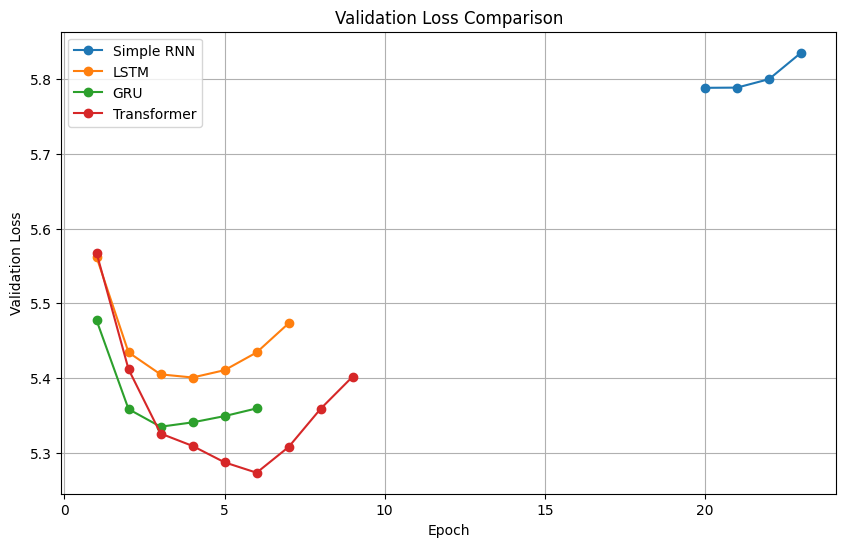

In [197]:
import matplotlib.pyplot as plt

# Prepare validation loss histories
validation_losses = {
    "Simple RNN": [best_rnn_checkpoint["val_loss"]] + rnn_checkpoint["val_loss_history"],
    "LSTM": lstm_checkpoint["val_loss_history"],
    "GRU": gru_checkpoint["val_loss_history"],
    "Transformer": transformer_checkpoint["val_loss_history"]
}

# Plot validation losses
plt.figure(figsize=(10, 6))

for model_name, losses in validation_losses.items():

    if model_name == "Simple RNN":
        epochs_range = range(20, 20 + len(losses))
    else:
        epochs_range = range(1, len(losses) + 1)

    plt.plot(epochs_range, losses, marker="o", label=model_name)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison") # plot tittle
plt.legend() # show the sign with their color
plt.grid(True)
plt.show()

## 11. Hyperparameter Tuning, Fine-Tuning and Final Model Selection


We will improve the selected model **Transformer** using it path **best_transformer.pth**  by experimenting with different hyperparameters, fine-tuning its architecture and training settings, and evaluating the results to determine the final model for next-word prediction.

In [198]:
#( Bringing out the architect and load first before further Tunning)
# Load the best Transformer checkpoint
best_transformer_checkpoint = torch.load( #loading it through it checkpoint
    BEST_TRANSFORMER_PATH, #it path tittle in var
    weights_only=False
)

# Restore the best model parameters
transformer_embedding.load_state_dict(
    best_transformer_checkpoint["transformer_embedding"]
)

transformer_position_embedding.load_state_dict(
    best_transformer_checkpoint["transformer_position_embedding"]
)

transformer_encoder.load_state_dict(
    best_transformer_checkpoint["transformer_encoder"]
)

transformer_fn_layer.load_state_dict(
    best_transformer_checkpoint["transformer_fn_layer"]
)

# Print the restored checkpoint details
print("BEST TRANSFORMER CHECKPOINT")
print("Best Epoch:", best_transformer_checkpoint["epoch"])
print(f"Best Validation Loss: {best_transformer_checkpoint['val_loss']:.4f}")

BEST TRANSFORMER CHECKPOINT
Best Epoch: 6
Best Validation Loss: 5.2736


We start by defining a new learning rate by changing it from LR = 0.001 to 0.0005

In [199]:
# Define a new learning rate
transformer_learning_rate = 0.0005

# Create a new optimizer for fine-tuning
transformer_optimizer = torch.optim.Adam(
    list(transformer_embedding.parameters()) +
    list(transformer_position_embedding.parameters()) +
    list(transformer_encoder.parameters()) +
    list(transformer_fn_layer.parameters()),
    lr=transformer_learning_rate
)

Proceeds by increasing dropout from 0.1 to 0.2

In [200]:
# Define the new dropout rate
transformer_dropout = 0.2

# Update dropout in each Transformer encoder layer
for layer in transformer_encoder.layers:

    layer.dropout.p = transformer_dropout
    layer.dropout1.p = transformer_dropout
    layer.dropout2.p = transformer_dropout
    layer.self_attn.dropout = transformer_dropout

New optimizer because of the tuning settings

In [201]:
# Create a new optimizer for dropout tuning
transformer_optimizer = torch.optim.Adam(
    list(transformer_embedding.parameters()) +
    list(transformer_position_embedding.parameters()) +
    list(transformer_encoder.parameters()) +
    list(transformer_fn_layer.parameters()),
    lr=0.001
)

Creating new checkpoint path for the tuned model **tuned_transformer.pth**

In [202]:
# Checkpoint paths for the tuned Transformer
TUNED_TRANSFORMER_PATH = os.path.join(CHECKPOINT_DIR, 'tuned_transformer.pth')
BEST_TUNED_TRANSFORMER_PATH = os.path.join(CHECKPOINT_DIR, 'best_tuned_transformer.pth')

Training and validating begin here using 40 epoch loops and patience stop = 3

In [203]:

# Set the maximum number of epochs and early stopping patience
epochs = 40
patience = 3

# Group all Transformer components together
tuned_transformer_layers = [
    transformer_embedding,
    transformer_position_embedding,
    transformer_encoder,
    transformer_fn_layer
]

# Check whether a previous tuning checkpoint exists
if os.path.exists(TUNED_TRANSFORMER_PATH):

    # Load the latest tuning checkpoint
    tuned_checkpoint = torch.load(
        TUNED_TRANSFORMER_PATH,
        map_location='cpu',
        weights_only=False
    )

    # Restore Transformer weights
    transformer_embedding.load_state_dict(tuned_checkpoint['transformer_embedding'])
    transformer_position_embedding.load_state_dict(tuned_checkpoint['transformer_position_embedding'])
    transformer_encoder.load_state_dict(tuned_checkpoint['transformer_encoder'])
    transformer_fn_layer.load_state_dict(tuned_checkpoint['transformer_fn_layer'])

    # Restore optimizer state
    transformer_optimizer.load_state_dict(tuned_checkpoint['optimizer_state_dict'])

    # Restore training and validation histories
    tuned_train_loss_history = tuned_checkpoint['train_loss_history']
    tuned_train_accuracy_history = tuned_checkpoint['train_accuracy_history']
    tuned_val_loss_history = tuned_checkpoint['val_loss_history']
    tuned_val_accuracy_history = tuned_checkpoint['val_accuracy_history']

    # Restore early stopping information
    tuned_best_val_loss = tuned_checkpoint['best_val_loss']
    tuned_patience_counter = tuned_checkpoint['patience_counter']

    # Restore the last completed epoch
    start_epoch = tuned_checkpoint['epoch']

    # Check whether early stopping was already triggered
    if tuned_patience_counter >= patience:

        print(f"\nEarly stopping triggered at epoch {start_epoch}.")
        print("The tuning experiment has already been completed.")

    else:

        print(f"Resuming from epoch {start_epoch + 1}")

else:

    # Initialise training and validation histories
    tuned_train_loss_history = []
    tuned_train_accuracy_history = []
    tuned_val_loss_history = []
    tuned_val_accuracy_history = []

    # Initialise early stopping information
    tuned_best_val_loss = float('inf')
    tuned_patience_counter = 0

    # Start from the first epoch
    start_epoch = 0

    print("Starting a new tuning experiment")


# Train and validate the tuned Transformer only if early stopping has not been triggered
if tuned_patience_counter < patience:

    for epoch in range(start_epoch, epochs):

        # Set all components to training mode
        for layer in tuned_transformer_layers:
            layer.train()

        # Initialise training metrics
        running_loss = 0.0
        total_correct = 0
        total_examples = 0

        # Train using the training DataLoader
        for input_batch, target_batch in train_loader:

            # Generate token embeddings
            embedded = transformer_embedding(input_batch)

            # Add positional embeddings
            positions = torch.arange(30, device=input_batch.device)
            position_embedded = transformer_position_embedding(positions)
            transformer_input = embedded + position_embedded

            # Create a causal mask to prevent access to future tokens
            causal_mask = torch.triu(
                torch.ones(30, 30, device=input_batch.device, dtype=torch.bool),
                diagonal=1
            )

            # Pass the input through the Transformer encoder
            output = transformer_encoder(transformer_input, mask=causal_mask)

            # Extract the final sequence position
            last_output = output[:, -1, :]

            # Generate next-word predictions
            predictions = transformer_fn_layer(last_output)

            # Calculate the loss
            loss = transformer_loss_function(predictions, target_batch)

            # Update model weights
            transformer_optimizer.zero_grad()
            loss.backward()
            transformer_optimizer.step()

            # Accumulate training loss and correct predictions
            running_loss += loss.item()
            predicted_tokens = torch.argmax(predictions, dim=1)
            total_correct += (predicted_tokens == target_batch).sum().item()
            total_examples += target_batch.size(0)

        # Calculate average training loss and accuracy
        epoch_loss = running_loss / len(train_loader)
        epoch_accuracy = (total_correct / total_examples) * 100

        # Store training metrics
        tuned_train_loss_history.append(epoch_loss)
        tuned_train_accuracy_history.append(epoch_accuracy)

        # Set all components to evaluation mode
        for layer in tuned_transformer_layers:
            layer.eval()

        # Initialise validation metrics
        val_running_loss = 0.0
        val_total_correct = 0
        val_total_examples = 0

        # Disable gradient calculations during validation
        with torch.no_grad():

            # Validate using the validation DataLoader
            for input_batch, target_batch in val_loader:

                # Generate token embeddings
                embedded = transformer_embedding(input_batch)

                # Add positional embeddings
                positions = torch.arange(30, device=input_batch.device)
                position_embedded = transformer_position_embedding(positions)
                transformer_input = embedded + position_embedded

                # Create a causal mask
                causal_mask = torch.triu(
                    torch.ones(30, 30, device=input_batch.device, dtype=torch.bool),
                    diagonal=1
                )

                # Pass the input through the Transformer encoder
                output = transformer_encoder(transformer_input, mask=causal_mask)

                # Extract the final sequence position
                last_output = output[:, -1, :]

                # Generate next-word predictions
                predictions = transformer_fn_layer(last_output)

                # Calculate validation loss
                val_loss = transformer_loss_function(predictions, target_batch)

                # Accumulate validation loss and correct predictions
                val_running_loss += val_loss.item()
                predicted_tokens = torch.argmax(predictions, dim=1)
                val_total_correct += (predicted_tokens == target_batch).sum().item()
                val_total_examples += target_batch.size(0)

        # Calculate average validation loss and accuracy
        val_epoch_loss = val_running_loss / len(val_loader)
        val_epoch_accuracy = (val_total_correct / val_total_examples) * 100

        # Store validation metrics
        tuned_val_loss_history.append(val_epoch_loss)
        tuned_val_accuracy_history.append(val_epoch_accuracy)

        # Display epoch results
        print(
            f"Epoch [{epoch + 1}/{epochs}] | "
            f"Train Loss: {epoch_loss:.4f} | "
            f"Train Accuracy: {epoch_accuracy:.2f}% | "
            f"Val Loss: {val_epoch_loss:.4f} | "
            f"Val Accuracy: {val_epoch_accuracy:.2f}%"
        )

        # Check whether validation loss has improved
        if val_epoch_loss < tuned_best_val_loss:

            # Update the best validation loss
            tuned_best_val_loss = val_epoch_loss
            tuned_patience_counter = 0

            # Save the best tuned Transformer checkpoint
            torch.save({
                'epoch': epoch + 1,
                'transformer_embedding': transformer_embedding.state_dict(),
                'transformer_position_embedding': transformer_position_embedding.state_dict(),
                'transformer_encoder': transformer_encoder.state_dict(),
                'transformer_fn_layer': transformer_fn_layer.state_dict(),
                'val_loss': tuned_best_val_loss
            }, BEST_TUNED_TRANSFORMER_PATH)

        else:

            # Increase the early stopping counter
            tuned_patience_counter += 1

        # Save the latest tuned Transformer checkpoint after every epoch
        torch.save({
            'epoch': epoch + 1,
            'transformer_embedding': transformer_embedding.state_dict(),
            'transformer_position_embedding': transformer_position_embedding.state_dict(),
            'transformer_encoder': transformer_encoder.state_dict(),
            'transformer_fn_layer': transformer_fn_layer.state_dict(),
            'optimizer_state_dict': transformer_optimizer.state_dict(),
            'train_loss_history': tuned_train_loss_history,
            'train_accuracy_history': tuned_train_accuracy_history,
            'val_loss_history': tuned_val_loss_history,
            'val_accuracy_history': tuned_val_accuracy_history,
            'best_val_loss': tuned_best_val_loss,
            'patience_counter': tuned_patience_counter
        }, TUNED_TRANSFORMER_PATH)

        # Stop training if validation loss does not improve
        if tuned_patience_counter >= patience:
            print(f"\nEarly stopping triggered at epoch {epoch + 1}.")
            break

# Display the final tuning results
print("\nTUNED TRANSFORMER TRAINING COMPLETED")
print(f"Last Completed Epoch: {start_epoch if tuned_patience_counter >= patience else epoch + 1}")
print(f"Best Validation Loss: {tuned_best_val_loss:.4f}")
print(f"Best Checkpoint: {BEST_TUNED_TRANSFORMER_PATH}")
print(f"Latest Checkpoint: {TUNED_TRANSFORMER_PATH}")



Early stopping triggered at epoch 6.
The tuning experiment has already been completed.

TUNED TRANSFORMER TRAINING COMPLETED
Last Completed Epoch: 6
Best Validation Loss: 5.3086
Best Checkpoint: /content/drive/MyDrive/Next-Word Prediction NLP/colab_models/best_tuned_transformer.pth
Latest Checkpoint: /content/drive/MyDrive/Next-Word Prediction NLP/colab_models/tuned_transformer.pth


In [204]:

# Load the latest tuned Transformer checkpoint
tuned_transformer_checkpoint = torch.load(
    TUNED_TRANSFORMER_PATH,
    map_location='cpu',
    weights_only=False
)

# Print tuned Transformer training losses
print("TUNED TRANSFORMER TRAINING LOSSES")
for epoch, loss in enumerate(tuned_transformer_checkpoint["train_loss_history"], start=1):
    print(f"Epoch {epoch}: {loss:.4f}")

# Print tuned Transformer training accuracy
print("\nTUNED TRANSFORMER TRAINING ACCURACY")
for epoch, accuracy in enumerate(tuned_transformer_checkpoint["train_accuracy_history"], start=1):
    print(f"Epoch {epoch}: {accuracy:.2f}%")

# Print tuned Transformer validation losses
print("\nTUNED TRANSFORMER VALIDATION LOSSES")
for epoch, loss in enumerate(tuned_transformer_checkpoint["val_loss_history"], start=1):
    print(f"Epoch {epoch}: {loss:.4f}")

# Print tuned Transformer validation accuracy
print("\nTUNED TRANSFORMER VALIDATION ACCURACY")
for epoch, accuracy in enumerate(tuned_transformer_checkpoint["val_accuracy_history"], start=1):
    print(f"Epoch {epoch}: {accuracy:.2f}%")

# Load the best tuned Transformer checkpoint
best_tuned_transformer_checkpoint = torch.load(
    BEST_TUNED_TRANSFORMER_PATH,
    map_location='cpu',
    weights_only=False
)

# Print the best tuned Transformer checkpoint details
print("\nBEST TUNED TRANSFORMER MODEL")
print("Best Epoch:", best_tuned_transformer_checkpoint["epoch"])
print(f"Best Validation Loss: {best_tuned_transformer_checkpoint['val_loss']:.4f}")


TUNED TRANSFORMER TRAINING LOSSES
Epoch 1: 5.3450
Epoch 2: 5.1003
Epoch 3: 5.0139
Epoch 4: 4.9608
Epoch 5: 4.9143
Epoch 6: 4.8508

TUNED TRANSFORMER TRAINING ACCURACY
Epoch 1: 21.00%
Epoch 2: 21.40%
Epoch 3: 21.72%
Epoch 4: 22.04%
Epoch 5: 22.30%
Epoch 6: 22.67%

TUNED TRANSFORMER VALIDATION LOSSES
Epoch 1: 5.3287
Epoch 2: 5.3086
Epoch 3: 5.3159
Epoch 4: 5.3172
Epoch 5: 5.3213
Epoch 6: 5.3456

TUNED TRANSFORMER VALIDATION ACCURACY
Epoch 1: 20.79%
Epoch 2: 21.05%
Epoch 3: 20.86%
Epoch 4: 20.95%
Epoch 5: 20.99%
Epoch 6: 20.82%

BEST TUNED TRANSFORMER MODEL
Best Epoch: 2
Best Validation Loss: 5.3086


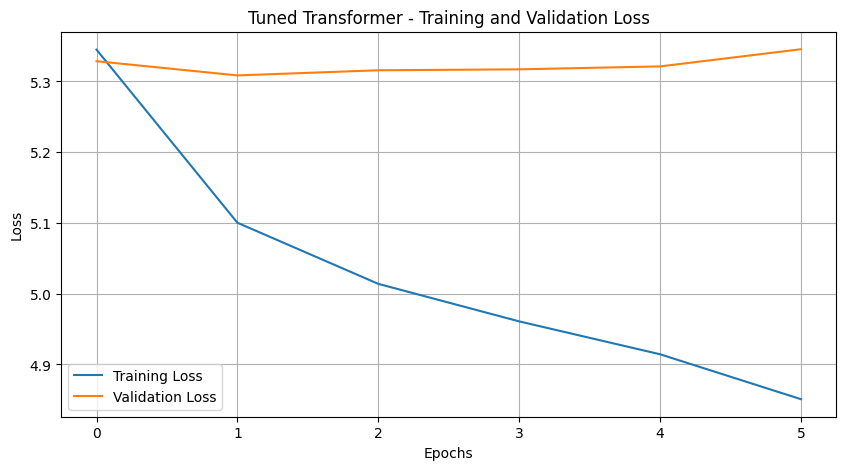

In [205]:
plt.figure(figsize=(10, 5))

plt.plot(tuned_transformer_checkpoint["train_loss_history"], label="Training Loss")
plt.plot(tuned_transformer_checkpoint["val_loss_history"], label="Validation Loss")

plt.title("Tuned Transformer - Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()

Increasing dropout from 0.1 to 0.2 did not solve the overfitting problem.

We should retain the original baseline checkpoint as our current best model.

## 12. Next-Word Prediction and Text Generation

We will use our trained models to make predictions on new text and generate sentences one word at a time.

We will use the original baseline Transformer, not the tuned Transformer, because it achieved the better validation loss (5.2736 compared with 5.3086).

Load the Best Transformer Checkpoint

In [206]:
# Load the best Transformer checkpoint
transformer_checkpoint = torch.load(
    BEST_TRANSFORMER_PATH,
    map_location='cpu',
    weights_only=False
)

# Restore the best Transformer weights
transformer_embedding.load_state_dict(transformer_checkpoint['transformer_embedding'])
transformer_position_embedding.load_state_dict(transformer_checkpoint['transformer_position_embedding'])
transformer_encoder.load_state_dict(transformer_checkpoint['transformer_encoder'])
transformer_fn_layer.load_state_dict(transformer_checkpoint['transformer_fn_layer'])

# Set all components to evaluation mode
transformer_embedding.eval()
transformer_position_embedding.eval()
transformer_encoder.eval()
transformer_fn_layer.eval()

print("Best Transformer checkpoint loaded successfully.")

Best Transformer checkpoint loaded successfully.


In [207]:

def predict_next_word(text, top_k=5):

    # Convert the input text to lowercase tokens
    tokens = text.lower().split()

    # Convert tokens to their vocabulary IDs
    token_ids = [vocab_size.get(token, unk_id) for token in tokens]

    # Keep the last 30 tokens
    token_ids = token_ids[-30:]

    # Convert token IDs into a PyTorch tensor
    input_tensor = torch.tensor([token_ids], dtype=torch.long)

    # Disable gradient calculations
    with torch.no_grad():

        # Generate token embeddings
        embedded = transformer_embedding(input_tensor)

        # Generate positional embeddings
        positions = torch.arange(len(token_ids))
        position_embedded = transformer_position_embedding(positions)

        # Combine token and positional embeddings
        transformer_input = embedded + position_embedded

        # Create a causal mask
        causal_mask = torch.triu(
            torch.ones(len(token_ids), len(token_ids), dtype=torch.bool),
            diagonal=1
        )

        # Pass the input through the Transformer encoder
        output = transformer_encoder(transformer_input, mask=causal_mask)

        # Extract the final sequence position
        last_output = output[:, -1, :]

        # Generate next-word predictions
        predictions = transformer_fn_layer(last_output)

        # Convert predictions into probabilities
        probabilities = torch.softmax(predictions, dim=1)

        # Get the top k predictions
        top_probabilities, top_indices = torch.topk(probabilities, top_k, dim=1)

    # Display the predicted words and probabilities
    for probability, token_id in zip(top_probabilities[0], top_indices[0]):

        predicted_word = next(
            (word for word, index in vocab_size.items() if index == token_id.item()),
            "<unk>"
        )

        print(f"{predicted_word}: {probability.item() * 100:.2f}%")

    # Get the highest-probability prediction
    best_token_id = top_indices[0][0].item()

    # Convert the token ID back to a word
    best_word = next(
        (word for word, index in vocab_size.items() if index == best_token_id),
        "<unk>"
    )

    return best_word


In [208]:
predicted_word = predict_next_word("the united states")
print(f"\nPredicted next word: {predicted_word}")

rifles: 3.24%
<unk>: 2.64%
": 2.28%
the: 2.18%
kilometers: 1.94%

Predicted next word: rifles


Now we will extend the prediction function to generate multiple words automatically.

The process is: **Autoregressive Text Generation.**
1. Start with an input prompt.
2. Predict the next token.
3. Add the predicted token to the prompt.
4. Repeat until we reach the requested number of generated tokens.

In [209]:
def generate_text(prompt, num_words=20, temperature=0.8):

    generated_tokens = prompt.lower().split()

    for _ in range(num_words):

        token_ids = [vocab_size.get(token, unk_id) for token in generated_tokens]
        token_ids = token_ids[-30:]

        input_tensor = torch.tensor([token_ids], dtype=torch.long)

        with torch.no_grad():

            embedded = transformer_embedding(input_tensor)

            positions = torch.arange(len(token_ids))
            position_embedded = transformer_position_embedding(positions)

            transformer_input = embedded + position_embedded

            causal_mask = torch.triu(
                torch.ones(len(token_ids), len(token_ids), dtype=torch.bool),
                diagonal=1
            )

            output = transformer_encoder(transformer_input, mask=causal_mask)

            last_output = output[:, -1, :]

            predictions = transformer_fn_layer(last_output)

            # Apply temperature
            predictions = predictions / temperature

            # Convert predictions into probabilities
            probabilities = torch.softmax(predictions, dim=1)

            # Sample the next token
            predicted_token_id = torch.multinomial(probabilities, num_samples=1).item()

        predicted_word = next(
            (word for word, index in vocab_size.items() if index == predicted_token_id),
            "<unk>"
        )

        generated_tokens.append(predicted_word)

    return " ".join(generated_tokens)

In [210]:
generated_text = generate_text(
    "the united states",
    num_words=20,
    temperature=0.8
)

print(generated_text)

the united states <unk> directions businesses " bank to us " the the <unk> lucky . next west @-@ west – south of


## 13. Evaluation on the final Model using Test Dataset

The test dataset has remained untouched. Now is the right time to use it to on the best saved model and apply evaluation metrics

In [211]:
# Set all Transformer components to evaluation mode
transformer_embedding.eval()
transformer_position_embedding.eval()
transformer_encoder.eval()
transformer_fn_layer.eval()

# Initialise test metrics
running_loss = 0.0
total_correct = 0
total_examples = 0

# Disable gradient calculations
with torch.no_grad():

    # Evaluate using the test DataLoader
    for input_batch, target_batch in test_loader:

        # Generate token embeddings
        embedded = transformer_embedding(input_batch)

        # Generate positional embeddings
        positions = torch.arange(30, device=input_batch.device)
        position_embedded = transformer_position_embedding(positions)

        # Combine token and positional embeddings
        transformer_input = embedded + position_embedded

        # Create a causal mask
        causal_mask = torch.triu(
            torch.ones(30, 30, device=input_batch.device, dtype=torch.bool),
            diagonal=1
        )

        # Pass the input through the Transformer encoder
        output = transformer_encoder(transformer_input, mask=causal_mask)

        # Extract the final sequence position
        last_output = output[:, -1, :]

        # Generate next-word predictions
        predictions = transformer_fn_layer(last_output)

        # Calculate test loss
        loss = transformer_loss_function(predictions, target_batch)

        # Accumulate test loss and correct predictions
        running_loss += loss.item() * target_batch.size(0)

        predicted_tokens = torch.argmax(predictions, dim=1)
        total_correct += (predicted_tokens == target_batch).sum().item()
        total_examples += target_batch.size(0)

# Calculate final test metrics
epoch_loss = running_loss / total_examples
test_accuracy = (total_correct / total_examples) * 100
test_perplexity = torch.exp(torch.tensor(epoch_loss)).item()

# Display test results
print("FINAL TRANSFORMER TEST RESULTS")
print(f"Test Loss: {epoch_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Test Perplexity: {test_perplexity:.2f}")
print(f"Correct Predictions: {total_correct}/{total_examples}")


FINAL TRANSFORMER TEST RESULTS
Test Loss: 5.2073
Test Accuracy: 21.55%
Test Perplexity: 182.60
Correct Predictions: 38509/178727


Accuracy checks whether the model guessed the correct next word. Perplexity measures how confident or uncertain its probability predictions are.

### Final Transformer Evaluation

The selected Transformer model was evaluated on the held-out test dataset after training and hyperparameter tuning were completed.

The model achieved a test loss of 5.2073, test accuracy of 21.55%, and perplexity of 182.60. It correctly predicted 38,509 out of 178,727 next-token targets.

The results provide an estimate of the model's ability to predict unseen text. Although its exact next-token accuracy is relatively modest, the model successfully demonstrates the implementation and evaluation of a Transformer-based next-word prediction language model using PyTorch.

In [212]:
all_predictions = []
all_labels = []

# Set all Transformer components to evaluation mode
transformer_embedding.eval()
transformer_position_embedding.eval()
transformer_encoder.eval()
transformer_fn_layer.eval()

# Disable gradient calculations
with torch.no_grad():

    for input_batch, target_batch in test_loader:

        embedded = transformer_embedding(input_batch)

        positions = torch.arange(30, device=input_batch.device)
        position_embedded = transformer_position_embedding(positions)

        transformer_input = embedded + position_embedded

        causal_mask = torch.triu(
            torch.ones(30, 30, device=input_batch.device, dtype=torch.bool),
            diagonal=1
        )

        output = transformer_encoder(transformer_input, mask=causal_mask)

        last_output = output[:, -1, :]
        predictions = transformer_fn_layer(last_output)

        predicted = torch.argmax(predictions, dim=1)

        all_predictions.extend(predicted.cpu().tolist())
        all_labels.extend(target_batch.cpu().tolist())

print("Total Predictions:", len(all_predictions))
print("Total Labels:", len(all_labels))

Total Predictions: 178727
Total Labels: 178727


In [213]:
# Import evaluation metrics, the 4 metrics are (accuracy_score, classification_report, confusion_matrix, roc_auc_score)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.metrics import accuracy_score, precision_recall_fscore_support


In [214]:
# Evaluate predictions for accuracy
accuracy = accuracy_score(all_labels, all_predictions)

# Calculate weighted precision, recall and F1-score
precision, recall, f1_score, _ = precision_recall_fscore_support(
    all_labels,
    all_predictions,
    average='weighted',
    zero_division=0
)

# Display classification metrics
print("FINAL TRANSFORMER CLASSIFICATION METRICS")
print(f"Accuracy: {accuracy:.4f}")
print(f"Weighted Precision: {precision:.4f}")
print(f"Weighted Recall: {recall:.4f}")
print(f"Weighted F1-Score: {f1_score:.4f}")

FINAL TRANSFORMER CLASSIFICATION METRICS
Accuracy: 0.2155
Weighted Precision: 0.1563
Weighted Recall: 0.2155
Weighted F1-Score: 0.1561


### Final Transformer Classification Evaluation

The selected Transformer model achieved an accuracy of 21.55%, weighted precision of 15.63%, weighted recall of 21.55%, and weighted F1-score of 15.61% on the held-out test dataset.

The results demonstrate that the model learned meaningful next-word prediction patterns, although its predictive performance remains limited across the large vocabulary.


## 14. Deployment and Documentation

In [215]:
# Save the final Transformer checkpoint
FINAL_TRANSFORMER_PATH = os.path.join(
    CHECKPOINT_DIR,
    'final_transformer.pth'
)

checkpoint = torch.load(BEST_TRANSFORMER_PATH, map_location='cpu')

torch.save(checkpoint, FINAL_TRANSFORMER_PATH)

print("Final Transformer model saved successfully.")

Final Transformer model saved successfully.


In [216]:
# Rebuild the Transformer architecture
transformer_embedding = nn.Embedding(num_tokens, 128)
transformer_position_embedding = nn.Embedding(30, 128)

encoder_layer = nn.TransformerEncoderLayer(
    d_model=128,
    nhead=4,
    dim_feedforward=512,
    batch_first=True
)

transformer_encoder = nn.TransformerEncoder(
    encoder_layer,
    num_layers=2
)

transformer_fn_layer = nn.Linear(128, num_tokens)

# Load the saved checkpoint
checkpoint = torch.load(FINAL_TRANSFORMER_PATH, map_location='cpu')

transformer_embedding.load_state_dict(checkpoint['transformer_embedding'])
transformer_position_embedding.load_state_dict(checkpoint['transformer_position_embedding'])
transformer_encoder.load_state_dict(checkpoint['transformer_encoder'])
transformer_fn_layer.load_state_dict(checkpoint['transformer_fn_layer'])

# Set all components to evaluation mode
transformer_embedding.eval()
transformer_position_embedding.eval()
transformer_encoder.eval()
transformer_fn_layer.eval()

print("Final Transformer model loaded successfully.")

Final Transformer model loaded successfully.


**Github Push**

In [217]:
from google.colab import userdata

import requests
import base64

token = userdata.get("GITHUB_TOKEN")

repo = "kenetworkltd-oss/Next-Word-Prediction-NLP"
file_path = "next_word_prediction.ipynb"
branch = "main"

with open("/content/drive/MyDrive/Next-Word Prediction NLP/next_word_prediction.ipynb", "rb") as file:
    notebook_content = file.read()

encoded_content = base64.b64encode(notebook_content).decode("utf-8")

url = f"https://api.github.com/repos/{repo}/contents/{file_path}"

headers = {
    "Authorization": f"Bearer {token}",
    "Accept": "application/vnd.github+json"
}

response = requests.get(
    url,
    headers=headers,
    params={"ref": branch}
)

sha = response.json()["sha"]

payload = {
    "message": "Update notebook with executed outputs",
    "content": encoded_content,
    "branch": branch,
    "sha": sha
}

response = requests.put(url, headers=headers, json=payload)

print(response.status_code)
print(response.json().get("html_url", response.json()))

403
{'message': 'Resource not accessible by personal access token', 'documentation_url': 'https://docs.github.com/rest/repos/contents#create-or-update-file-contents', 'status': '403'}


In [218]:
import json

notebook_data = json.loads(notebook_content)

code_cells = [
    cell for cell in notebook_data["cells"]
    if cell["cell_type"] == "code"
]

executed_cells = [
    cell for cell in code_cells
    if cell.get("execution_count") is not None
]

cells_with_outputs = [
    cell for cell in code_cells
    if cell.get("outputs")
]

print("Total code cells:", len(code_cells))
print("Executed cells:", len(executed_cells))
print("Cells with outputs:", len(cells_with_outputs))

Total code cells: 266
Executed cells: 97
Cells with outputs: 59
